# E91 · The price signal and the substation: how many homes for how many kilowatts?

| | |
|---|---|
| **Type** | Advanced worked example - read, run, modify. Part of the large-model series, at its small rung only |
| **Data** | Real: Low Carbon London smart meters from UK Power Networks on the London Datastore, CC BY 4.0, and the trial's 2013 price file. 167.9 million half-hours from 5,561 homes, cut down here to three derived files (4.8 MB): hourly group means, a home x event table for 1,088 tariff homes, and the hourly meters of 200 homes. Changed from the source by aggregation and fitting |
| **Time** | About 3 minutes on 2 cores (measured), and about 2 of those are the 20 Student-t fits. A laptop may differ, and it was not measured. No GPU is used |
| **You will learn** | Saying what was randomised and what was not, and labelling every claim by which · a within-home closed-form fleet that runs in seconds · a placebo on the months before any price existed · why a robust likelihood can get a sum wrong · a crossed day-level model on event means · why homes do not buy certainty and evenings do · cross-fitting a "best responders" claim · turning a posterior into a procurement sentence · block-mean carpets, funnels and calendar rasters in plain matplotlib |

## The brief

> *From a network planner at a London distribution operator. The planner, the operator and the
> substation are fictional, invented for this notebook, because the public data carry no location.
> The meters, the prices and the trial are real.* We can reinforce a substation, or we can pay for a
> price signal. Before I put a price signal in the plan I need a sentence I can defend: how many
> homes do we have to sign up to have a stated chance of taking a stated number of kilowatts off the
> evening peak, on the day we need it? Is it worth chasing the best responders, or do we enrol
> everyone? And how far can a 2013 London trial be trusted for that?

## The answer, before the working

**Do not put the price signal in the plan as firm capacity. Run a local trial first, and make it a
trial of winter evenings.** Nobody tossed a coin for who got the tariff. Somebody did toss a coin
for which days had Supply-Following (SF) price events. Every claim below rests on those days, and on
a winter evening there are four of them.

- **What a price event does.** On a randomised evening High-price event, a home on the tariff used
  about 29-42 W less than its own baseline, out of an evening load near 550 W. That is a mean over the
  priced hours, not a cut at the peak hour. The range is the choice of baseline. Section 4 argues for
  the 2013 end, but only after seeing the placebo, so the range stays. Each end also has its own
  interval from 15 events: about -23 to -36 W and -35 to -47 W. For a winter evening alone it is about
  37-40 W on all 4 events, or about 55 W on 3 if 28 December is left out. These are volunteers, paid
  and protected against losing money. Every figure here rests on the 15 randomised evenings. The
  placed peak days are out of the model and out of the baselines behind these figures.
- **How many homes.** Offer 100,000 homes at an assumed 24% acceptance and the chance of taking 1 MW
  off one winter evening, as a mean over its priced hours, is about 0.4-0.5. Without 28 December it is
  about 0.7-0.9, and without either February evening about 0.2-0.4. The 24% has no traced source, so
  it is the planner's number to set. One evening moves the answer that far, in either direction,
  which is the whole finding: **four evenings limit this, not 1,088 homes.** Measured at the
  18:00-20:00 peak itself the first figure is about 0.5-0.6, but only 3 of the 4 evenings priced
  those hours.
- **What 28 December is.** It does not stand alone. Every SF event after 19 December shows nothing,
  Low prices included. We cannot tell a signal not sent from Christmas week. Two more explanations are
  untested: it was the weakest of the five evening event types, and the SF High response fades
  through 2013.
- **Why more homes do not fix it.** At 200,000 offers, counting homes says a certainty. Counting
  evenings says about 0.7 to about 0.97, depending on the baseline and on how far a winter evening is
  allowed to stray. If you take the four evenings at face value, one in four falls short at any scale
  a planner would consider. A model that lets winter vary gives about 0.72 at 200,000 offers and about
  0.8 near 330,000, and four evenings cannot settle which is right. The shared-spread model, which
  gives the higher figures, treats 28 December as ordinary noise, and that evening is the one its own
  predictive check misses. How often such an evening recurs is an input: 1 in 4 is the raw count, and
  about 1 in 11, a post-hoc sensitivity, if it is confined to a Christmas fortnight.
- **Chasing the best responders.** They exist, and on held-out events the top quartile is worth about
  2.2x the average. The published figure is 3x, but same-event ranking here reads 4.9x, so the two were
  not built alike and that is no clean comparison. About half of what same-event ranking claims does
  not repeat, and that ranking needs response history no operator holds before a trial. Ranking on
  earlier evening load alone gives about 1.6x on all 15 events and 1.8x on the winter four. Both lists
  pick bigger homes: as a share of load the 2.2x is about 1.7x, and the load-ranked list shows no
  larger a share than everyone.
- **How far to trust it.** The within-home checks passed on balance and on the published benchmark.
  The pre-trial placebo **failed its gate**, below the line that would have ended the estimate. So
  this is a reduced delivery estimate, reported only as a range on the randomised events. The
  non-randomised peak days appear in two delivery rows, beside their placebo and outside every range
  above, and they carry nothing.
- **What the expensive model did.** The Student-t household fit was the plan's main model. Its
  location failed on SF Low and on the placed CM band, where it read about an eighth and a quarter of
  the mean. On the randomised High band the gap is not clearly separated from the choice of baseline.
  M1 stays because a sum needs means, not because Student-t was shown wrong on the headline band. The
  closed-form fit takes seconds and carries every kW figure here.

**Numbers in the prose are ranges or rounded, and your run may differ.** Results depend on the state of
the compile cache as well as on the seed. We ran this source on 2 cores at the same seed in three
states: PyTensor's default directory, which did not yet hold these event models, an empty directory,
and a full one. The first two printed the same event-model numbers, and differed only in the Student-t
diagnostics (median minimum ESS 2,792 against 2,855) and in timings. The full one moved some event-model
medians by a few tenths of a watt, the ends of own-spread intervals by up to 2 W, and printed chances by
at most 0.01, except one peak-hours row, which moved by 0.03. The homes needed for P = 0.95 without 28 December read about 208,000 and 215,000, because
the curve is nearly flat there, and that row has read 601,000 on an earlier fit. Section 6 says which
setting was changed to stop one fit going badly wrong on a first run. nutpie is not promised to be
bit-reproducible, and another core count may differ. The fleet tables and the pilot figures are stored
results, so a run does not change them.

## Modelling decisions, stated up front

| Decision | What this notebook does | Why, and what it costs |
|---|---|---|
| **Scope** | The small rung: 200 homes' meters, a stored home x event table for 1,088 homes, one laptop-sized run | The full fleet has no route under the rules for this machine (2 cores, no soak). `PYMC_CHALLENGES_RUN=full` stops with an error |
| **Causal contrast** | Randomised Supply-Following (SF) event days, within tariff homes | Homes chose the tariff, so tariff vs flat is **never** an effect here. Flat homes only measure shared day shocks |
| **Peak days** | Constraint-Management (CM) days are shown, labelled **not randomised**, with their placebo beside them | The placebo gate failed, so its written action applies: only the SF range is reported. They enter no fit behind a headline. Two delivery rows use them, labelled, outside every range |
| **Estimand** | A home's mean hourly load over the priced hours of an announced 2013 event, against that home's baseline, which is fitted to its hours with no event term. An evening cell is the priced hours inside 17:00-23:00: 3 or 6 hours, not one peak hour | Among homes that accepted two opt-ins, passed filters and were paid to stay. It is not "the effect of offering a tariff". So "1 MW off an evening" below is a mean over those hours |
| **Clock** | Meter stamps are GMT all year and mark the end of a half-hour | Settled on all tariff homes in the pilot. Section 3 shows the size of the mistake |
| **Calendar** | 29 March reinstated as a CM day. 3 May and six days found only in the price file are out of events and baseline. The 3 all-Low days are out of the baseline | The owner's defaults, from a pilot whose own gate failed as written |
| **28 December** | Kept, and every delivery result is shown with and without it | It is one of four randomised winter evenings and shows no response. Dropping it would select on the outcome. Keeping it blind would hide the largest single swing here |
| **Baseline** | Two are carried: July 2012-February 2014, and 2013 with month x band terms. CM hours are left out of the fit behind the event table, M4 and every delivery figure | The second was chosen after seeing the placebo, so it is post-hoc. Together they make the reported range. A CM cell's mean was already absorbed by its own term, but its shape reached the hour levels, by up to 0.7 W on an SF evening |
| **Mean, not typical hour** | M1, a Gaussian fit with conjugate priors, carries all kW. Student-t is shown only for its failure | A substation adds up means. Pilot P10 failed, and its written action is this choice |
| **Day-level model** | Gaussian on event means, with `mu` by group, a day effect, and known between-home noise | Post-hoc, replacing the plan's Student-t version on home x event cells, which gave `nu` at its floor and locations unlike the mean |
| **Day spread** | Two versions, both on the 15 SF evenings only: one spread for all of them, and one where the 4 winter evenings have their own | The first misses 28 December in its own predictive check. The second leans on its prior, because 4 evenings cannot bound a spread. Both are shown. Leaving out the 17 placed CM evenings is what gate P5 requires, and it costs the spread some precision |
| **Acceptance** | An axis, with 24% marked as an assumption | The "24% uptake" in the slides has no denominator we could trace |
| **Left out** | Student-t fleet beyond 100 homes, the two-stage pooling models M3a and M3b, the joint check M5, SBC beyond a 10-replicate smoke test, plasmode, any throughput or GPU figure, household-tail claims | Section 9 says what each would have told us. **Recovery of a known response on real noise is unvalidated** |

"The pilot" means the checks run before this notebook was written, recorded in `plans/large/E91.md`
and stored in `results/E91/`. The gates for P4-P11 were written to a file before they ran, and none
changed. P1-P3 had their gates in the plan, and P2's failed as written.
Figures from Report A3 and the trial's slides are marked **published**: they were not reproduced here.

## The plan

1. Who chose what, and what the coin decided
2. The first failure: comparing the two groups
3. The second failure: the clock
4. The fix: each home against itself, and the third failure
5. The fourth failure: the robust model
6. Every evening counts
7. How many homes? The fifth failure
8. The best responders, and the sixth failure
9. What this cost, what is missing, and what to tell the planner

In [1]:
import os

for name in ("OPENBLAS_NUM_THREADS", "OMP_NUM_THREADS", "MKL_NUM_THREADS"):
    os.environ.setdefault(name, "1")  # before NumPy: one BLAS thread per chain
os.environ.setdefault("JAX_PLATFORMS", "cpu")  # nothing here uses a GPU

import contextlib
import logging
import sys
import time

import arviz as az
import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import numpy as np
import nutpie
import pandas as pd
import pymc as pm
import scipy.sparse as sparse
from matplotlib.colors import BoundaryNorm, ListedColormap, LogNorm, TwoSlopeNorm
from matplotlib.patches import FancyArrowPatch, FancyBboxPatch, Patch
from matplotlib.ticker import FuncFormatter
from scipy import stats

from pymc_challenges import data
from pymc_challenges.bigrun import PreflightError, Store, banner, estimated, git_hash, measured

# ArviZ leaves a lazy stub under "jax", and Matplotlib's first plot tests it, which would import all of
# JAX for nothing (see E89). Nothing here uses JAX, so the stub goes.
sys.modules.pop("jax", None)

RANDOM_SEED = 91
rng = np.random.default_rng(RANDOM_SEED)
az.style.use("arviz-variat")
logging.getLogger("pymc").setLevel(logging.WARNING)

LEVEL = os.environ.get("PYMC_CHALLENGES_RUN", "").strip().lower() or "small"
if LEVEL != "small":
    raise PreflightError(
        f"PYMC_CHALLENGES_RUN={LEVEL!r}: E91 has one level, small. The household fleet "
        "and SBC have no route under this machine's rules, so nothing can be replayed."
    )

CORES = len(os.sched_getaffinity(0)) if hasattr(os, "sched_getaffinity") else os.cpu_count()
CHAINS_AT_ONCE = min(4, CORES)
SF_C, CM_C, DUD_C, MUTED, INK = "#0072b2", "#d55e00", "#b0226f", "#8a8a8a", "#2b2b2b"  # randomised, placed, 28 Dec
SKY = "#3f8fc4"  # a second blue, at least 3:1 on white
GATE_BANDS = ("SF High evening", "SF Low evening", "CM High evening")
GROUPS = ("SF winter", "SF summer", "CM winter", "CM summer")  # winter: GMT months; summer: BST months. CM: one row only
ACCEPTANCE = 0.24  # an assumption: the slides' uptake has no traced denominator
DUD_DAY = "2013-12-28"
PRICE = {}


@contextlib.contextmanager
def stage(name):
    """Add the time spent in this block to the price table printed at the end."""
    start = time.perf_counter()
    yield
    PRICE[name] = PRICE.get(name, 0.0) + time.perf_counter() - start


print(f"{CORES} cores here: {CHAINS_AT_ONCE} chains at once")

2 cores here: 2 chains at once


In [2]:
banner(
    wall_time=measured("3.1-3.3", "min on 2 cores, builds of 2026-11-02, default and empty compile cache"),
    peak_ram=measured("0.9-1.2", "GB, whole process tree, full and empty compile cache"),
    peak_vram=measured(0, "GB: no GPU, and JAX never executes"),
    disk=measured(4.8, "MB in data/, and under 0.5 MB of JSON in results/E91/"),
    download=measured(0, "MB: the tables are built by tools/build_e91_data.py from the 796 MB release"),
    precision=measured("float64", ""),
    chains=measured(4, "chains: 20 Student-t fits at 500 draws, 20 event-mean fits at 1,000 draws"),
    hardware=measured("Ryzen 5950X, on 2 cores", ""),
    build_date=measured("2026-11-02", ""),
    git_hash=measured(git_hash() or "unknown", ""),
    smaller_machine=estimated("this is the small problem: no larger level exists", ""),
)

| | Value | Status |
|---|---|---|
| Wall time | 3.1-3.3 min on 2 cores, builds of 2026-11-02, default and empty compile cache | measured |
| Peak RAM | 0.9-1.2 GB, whole process tree, full and empty compile cache | measured |
| Peak VRAM | 0 GB: no GPU, and JAX never executes | measured |
| Disk | 4.8 MB in data/, and under 0.5 MB of JSON in results/E91/ | measured |
| Download size | 0 MB: the tables are built by tools/build_e91_data.py from the 796 MB release | measured |
| Precision | float64 | measured |
| Chains | 4 chains: 20 Student-t fits at 500 draws, 20 event-mean fits at 1,000 draws | measured |
| Hardware | Ryzen 5950X, on 2 cores | measured |
| Build date | 2026-11-02 | measured |
| Git hash | 4aee16b77029-dirty | measured |
| On a smaller machine | this is the small problem: no larger level exists | estimated |

## 1. Who chose what, and what the coin decided

The release is big, and a notebook does not need most of it. `tools/build_e91_data.py` reduces 167.9
million half-hours to three files. Everything in them is a real reading, a mean of real readings,
or a closed-form fit to each home's readings. Home numbers are the public anonymous `LCLid` numbers:
the release has no address, substation, survey or demographic column.

In [3]:
data.describe("e91_hours")
data.describe("e91_event_table")
data.describe("lcl_small")
hour_file = np.load(data.path("e91_hours"))
table_file = np.load(data.path("e91_event_table"))
meter_file = np.load(data.path("lcl_small"))

store = Store("E91")
counts = store.load_json("pilot_counts")
tou_homes, std_homes = counts["homes_tou"], counts["homes_std"]
print(
    f"\n{counts['rows']:,} rows, {counts['homes']:,} homes with a usable reading: {tou_homes:,} on the tariff, "
    f"{std_homes:,} flat. Span {counts['first_slot'][:10]} to {counts['last_slot'][:10]}."
)

e91_hours: NumPy archive, not a table: open data.path() with np.load. One value per hour from 2012-07-01 00:00 GMT, 14,591 hours, meters read as gmt_end: fleet_kw (mean of the 1,088 ToU homes with at least 50% of 2013), fleet_homes, panel_kw (mean of the Std homes with at least 80% of the window), panel_homes, effect (number into `effects`, -1 for no event), cell (event-cell number, -1 for none), out_of_baseline (the owner's excluded days), placebo_effect and placebo_out (the same for the calendar moved back 364 days). Group means only, no home appears.
  source: UK Power Networks, Low Carbon London, SmartMeter Energy Consumption Data in London Households, London Datastore, CC BY 4.0, with the 2013 dynamic time-of-use tariff file. Changed: half-hourly readings aggregated and joined to the price calendar. DERIVED by tools/build_e91_data.py table - keep the cached file. No endorsement by UK Power Networks is implied.
  url:    https://data.london.gov.uk/dataset/smartmeter-energy-consumpt

In [4]:
def watts(array):
    """Whole watts as stored, with the missing marker turned into NaN."""
    out = array.astype(float)
    out[array == -32768] = np.nan
    return out


n_hours = hour_file["fleet_kw"].size
gmt = pd.date_range(str(hour_file["first_hour"]), periods=n_hours, freq="h")
wall = gmt.tz_localize("UTC").tz_convert("Europe/London").tz_localize(None)
hour_of_day = wall.hour.to_numpy()
band = np.select(
    [
        (hour_of_day >= 5) & (hour_of_day < 11),
        (hour_of_day >= 11) & (hour_of_day < 17),
        (hour_of_day >= 17) & (hour_of_day < 23),
    ],
    [0, 1, 2],
    3,
)  # morning, day, evening, night
level = hour_of_day * 2 + (wall.dayofweek.to_numpy() >= 5)  # s(t): wall hour x weekday or weekend
trial_day = (wall - pd.Timedelta(hours=5)).strftime("%Y-%m-%d").to_numpy().astype(str)  # days run 05:00-05:00
in_2013 = (gmt >= "2013-01-01") & (gmt < "2014-01-01")
pre_trial = gmt < "2013-01-01"
after_trial = gmt >= "2014-01-01"

fleet_kw, panel_kw = hour_file["fleet_kw"].astype(float), hour_file["panel_kw"].astype(float)
effect = hour_file["effect"].astype(int)
EFFECTS = [str(e) for e in hour_file["effects"]]
usable = ~hour_file["out_of_baseline"] & np.isfinite(panel_kw) & np.isfinite(fleet_kw)

cells = pd.DataFrame({c[5:]: table_file[c] for c in table_file.files if c.startswith("cell_")})
placebo_cells = pd.DataFrame(
    {
        c[8:]: table_file[c]
        for c in table_file.files
        if c.startswith("placebo_") and c not in ("placebo_homes", "placebo_w", "placebo_sigma_w")
    }
)
for frame in (cells, placebo_cells):
    frame["day"] = frame["day"].astype(object)
    frame["effect"] = frame["effect"].astype(object)
    frame["season"] = frame["season"].astype(object)
home_tables = {"local": watts(table_file["local_w"]), "plan": watts(table_file["plan_w"])}
placebo_table = watts(table_file["placebo_w"])
print(
    f"{n_hours:,} hours from {gmt[0]:%Y-%m-%d} GMT. Fleet {home_tables['local'].shape[0]:,} homes x "
    f"{len(cells)} event cells; placebo {placebo_table.shape[0]:,} homes x {len(placebo_cells)} cells; "
    f"flat panel {int(hour_file['n_panel']):,} homes."
)
print(cells.groupby("effect", sort=False).agg(cells=("hours", "size"), hours=("hours", "sum")).T.to_string())

14,591 hours from 2012-07-01 GMT. Fleet 1,088 homes x 168 event cells; placebo 963 homes x 70 cells; flat panel 4,090 homes.
effect  SF Low day  SF High night  SF Low night  SF High day  SF High morning  CM Low  CM High evening  SF Low morning  SF Low evening  CM High other  SF High evening
cells           15             12            12           15               12      40               17              12              15              3               15
hours           72             54            54           72               54     368              102              54              72             10               72


The whole design fits on one page, and two different things happened on it. The first is who ended
up on the tariff, which was a chain of choices. The second is which days carried a price event,
and for one family of events that was a draw.

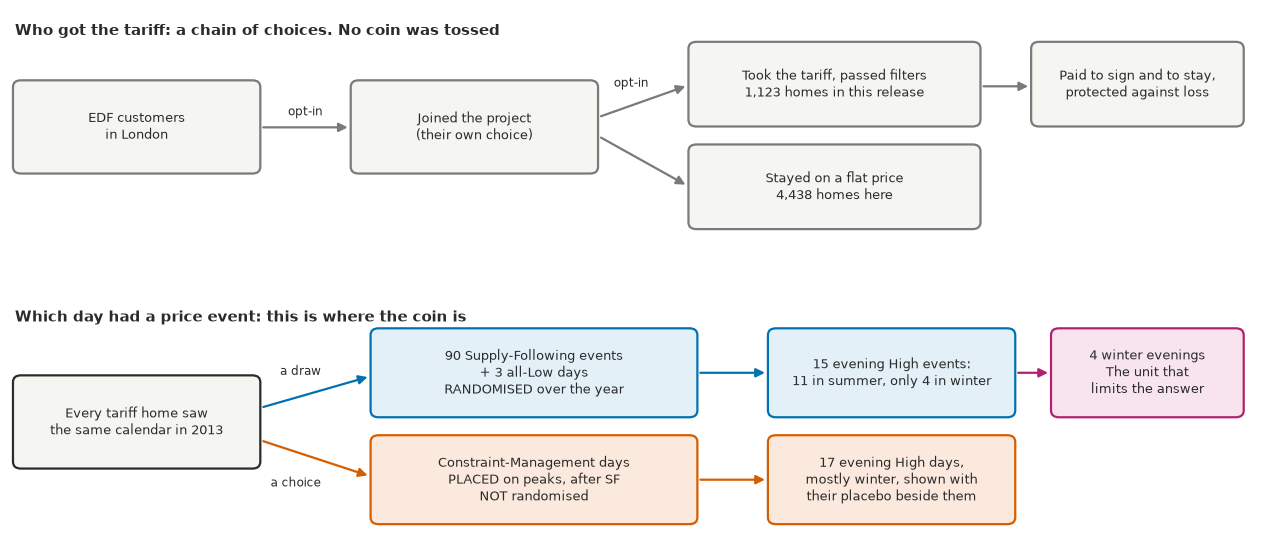

In [5]:
fig, ax = plt.subplots(figsize=(12.5, 5.3), layout="constrained")
ax.set(xlim=(0, 12.5), ylim=(0, 6.1))
ax.axis("off")


def box(x, y, text, colour, width=2.45, height=1.05, tint=None):
    ax.add_patch(
        FancyBboxPatch(
            (x, y),
            width,
            height,
            boxstyle="round,pad=0.02,rounding_size=0.08",
            facecolor=tint or "#f5f5f2",
            edgecolor=colour,
            linewidth=1.6,
        )
    )
    ax.text(x + width / 2, y + height / 2, text, ha="center", va="center", fontsize=9.5, color=INK)


def arrow(start, end, label, colour, offset=(0, 0.14), style="-|>"):
    ax.add_patch(
        FancyArrowPatch(start, end, arrowstyle=style, mutation_scale=13, color=colour, lw=1.6, shrinkA=0, shrinkB=0)
    )
    ax.text(
        (start[0] + end[0]) / 2 + offset[0],
        (start[1] + end[1]) / 2 + offset[1],
        label,
        ha="center",
        fontsize=8.8,
        color=INK,
    )


CHOICE = "#7a7a7a"
ax.text(
    0.05, 5.8, "Who got the tariff: a chain of choices. No coin was tossed", fontsize=11, weight="bold", color=INK
)
ax.text(0.05, 2.45, "Which day had a price event: this is where the coin is", fontsize=11, weight="bold", color=INK)
box(0.05, 4.2, "EDF customers\nin London", CHOICE)
box(3.45, 4.2, "Joined the project\n(their own choice)", CHOICE)
box(
    6.85,
    4.75,
    f"Took the tariff, passed filters\n{tou_homes:,} homes in this release",
    CHOICE,
    width=2.9,
    height=0.95,
)
box(6.85, 3.55, f"Stayed on a flat price\n{std_homes:,} homes here", CHOICE, width=2.9, height=0.95)
box(10.3, 4.75, "Paid to sign and to stay,\nprotected against loss", CHOICE, width=2.1, height=0.95)
arrow((2.55, 4.72), (3.4, 4.72), "opt-in", CHOICE)
arrow((5.95, 4.85), (6.8, 5.2), "opt-in", CHOICE, offset=(-0.12, 0.17))
arrow((5.95, 4.6), (6.8, 4.05), "", CHOICE)
arrow((9.8, 5.2), (10.25, 5.2), "", CHOICE)
box(0.05, 0.75, "Every tariff home saw\nthe same calendar in 2013", INK)
box(
    3.65,
    1.35,
    "90 Supply-Following events\n+ 3 all-Low days\nRANDOMISED over the year",
    SF_C,
    width=3.25,
    height=1.0,
    tint="#e3f0f8",
)
box(
    3.65,
    0.1,
    "Constraint-Management days\nPLACED on peaks, after SF\nNOT randomised",
    CM_C,
    width=3.25,
    height=1.0,
    tint="#fbe9dd",
)
box(
    7.65,
    1.35,
    "15 evening High events:\n11 in summer, only 4 in winter",
    SF_C,
    width=2.45,
    height=1.0,
    tint="#e3f0f8",
)
box(10.5, 1.35, "4 winter evenings\nThe unit that\nlimits the answer", DUD_C, width=1.9, height=1.0, tint="#f8e4ef")
box(
    7.65,
    0.1,
    "17 evening High days,\nmostly winter, shown with\ntheir placebo beside them",
    CM_C,
    width=2.45,
    height=1.0,
    tint="#fbe9dd",
)
arrow((2.55, 1.45), (3.6, 1.8), "a draw", SF_C, offset=(-0.15, 0.2))
arrow((2.55, 1.05), (3.6, 0.65), "a choice", CM_C, offset=(-0.2, -0.33))
arrow((6.95, 1.85), (7.6, 1.85), "", SF_C)
arrow((6.95, 0.6), (7.6, 0.6), "", CM_C)
arrow((10.15, 1.85), (10.45, 1.85), "", DUD_C);

Read the top row as a warning and the bottom row as the opportunity. Tariff homes are not a random
draw from anything, and the guide to the trial says so in plain words: the flat group "was not a true
control". Only the blue line of the bottom row carries a causal claim, and the magenta box is what
is left of it for the planner's question.

Here is the year itself. Each column is a day and each row is a half-hour, on trial days that run
05:00 to 05:00. Blue is randomised, orange is placed. The dashed lines mark the evening peak.

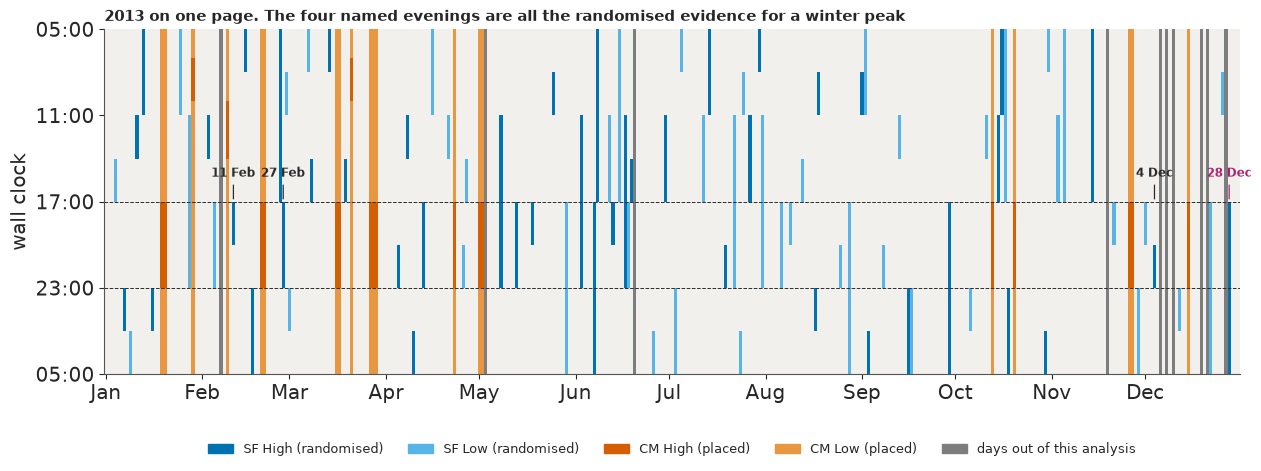

In [6]:
calendar = store.load_json("calendar")
days_2013 = pd.date_range("2013-01-01", "2013-12-31", freq="D")
day_row = {d.strftime("%Y-%m-%d"): i for i, d in enumerate(days_2013)}
year = np.zeros((48, len(days_2013)), dtype=int)  # 0 default, 1-2 SF Low/High, 3-4 CM Low/High
OUT_DAYS = sorted(set(trial_day[hour_file["out_of_baseline"]]))
for e in calendar["events"]:
    if e["day"] in OUT_DAYS or e["day"] == "2013-03-29" or e["day"] not in day_row:
        continue
    start = pd.Timestamp(e["start_wall"])
    first = ((start.hour - 5) % 24) * 2 + start.minute // 30
    kind = (1 if e["band"] == "Low" else 2) + (0 if e["class"] == "single" else 2)
    year[first : first + e["slots"], day_row[e["day"]]] = kind
year[0:24, day_row["2013-03-29"]], year[24:36, day_row["2013-03-29"]], year[36:48, day_row["2013-03-29"]] = 3, 4, 3
for day in OUT_DAYS:
    if day in day_row:
        year[:, day_row[day]] = 5

colours = ["#f1f0ec", "#56b4e9", SF_C, "#e8963f", CM_C, "#7d7d7d"]
fig, ax = plt.subplots(figsize=(12.5, 4.6), layout="constrained")
ax.imshow(
    year,
    aspect="auto",
    interpolation="nearest",
    cmap=ListedColormap(colours),
    norm=BoundaryNorm(np.arange(-0.5, 6), 6),
    extent=(-0.5, 364.5, 29, 5),
)
ax.axhline(17, color=INK, lw=0.7, ls="--")
ax.axhline(23, color=INK, lw=0.7, ls="--")
sf_evening = cells[cells["effect"] == "SF High evening"]
winter = sf_evening[sf_evening["season"] == "gmt"]
for _, row in winter.iterrows():
    ax.annotate(
        pd.Timestamp(row["day"]).strftime("%-d %b"),
        (day_row[row["day"]], 17),
        xytext=(0, 18),
        textcoords="offset points",
        ha="center",
        fontsize=8.5,
        color=DUD_C if row["day"] == DUD_DAY else INK,
        weight="bold",
        arrowprops=dict(arrowstyle="-", color=DUD_C if row["day"] == DUD_DAY else INK, lw=0.9),
    )
months = pd.date_range("2013-01-01", "2013-12-01", freq="MS")
ax.set_xticks([day_row[m.strftime("%Y-%m-%d")] for m in months], [m.strftime("%b") for m in months])
ax.set_yticks([5, 11, 17, 23, 29], ["05:00", "11:00", "17:00", "23:00", "05:00"])
ax.set_ylabel("wall clock")
ax.legend(
    handles=[
        Patch(color=colours[2], label="SF High (randomised)"),
        Patch(color=colours[1], label="SF Low (randomised)"),
        Patch(color=colours[4], label="CM High (placed)"),
        Patch(color=colours[3], label="CM Low (placed)"),
        Patch(color=colours[5], label="days out of this analysis"),
    ],
    loc="lower center",
    ncols=5,
    bbox_to_anchor=(0.5, -0.27),
    fontsize=9,
)
ax.set_title(
    "2013 on one page. The four named evenings are all the randomised evidence for a winter peak",
    loc="left",
    fontsize=11,
);

SF blocks sweep the clock evenly, which is the design. Most blue evening blocks fall between April
and September, when evening load is low. The orange blocks cluster in the months a planner cares
about, which is why they are tempting, and why nobody should treat them as a coin toss.

Eight days are in dispute between the price file and the published table. The pilot found that a
known peak day could fail its own test, so that gate was too weak. The contrast added after the fact
supports the table: 29 March behaves like a peak day and comes back, while 3 May and six file-only
days stay out. Those 7 days and the 3 all-Low days are the grey columns.

## 2. The first failure: comparing the two groups

The obvious first analysis, M0, takes tariff homes minus flat homes during price events. It is
fast, it gives a number, and the number looks plausible. The check is to run the same subtraction
where no price could be acting.

                                         tariff minus flat (W)  hours
where                                                                
SF High evening event                                    -68.7     72
CM High evening event                                    -84.7    102
2013 evenings on days with no event                      -36.4   1470
Jul-Dec 2012 evenings, no price existed                  -18.3   1104
Jan-Feb 2014 evenings, prices over                       -40.3    348


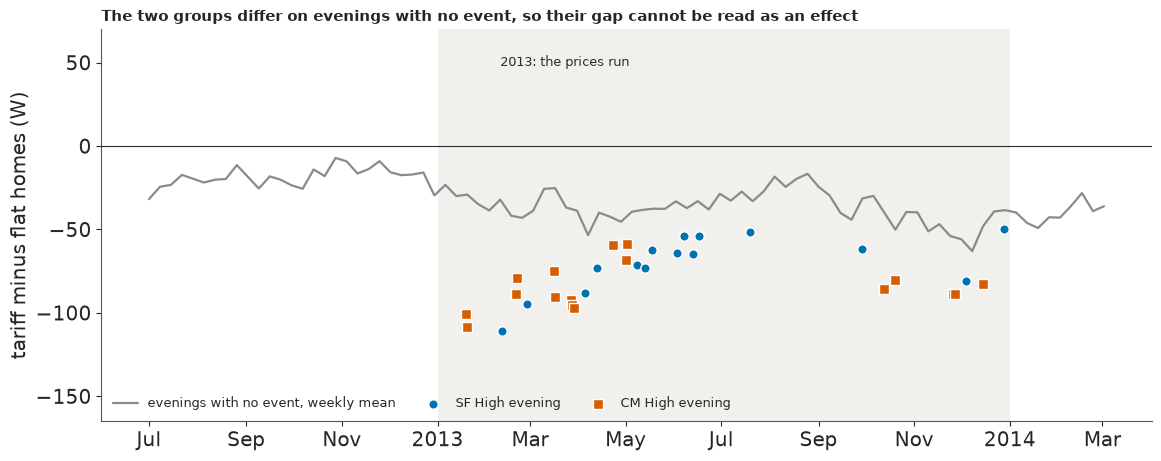

In [7]:
gap = 1000 * (fleet_kw - panel_kw)
evening = band == 2
event_days = np.unique(trial_day[effect >= 0])
quiet = evening & ~np.isin(trial_day, event_days) & usable


def m0_row(label, mask):
    return {"where": label, "tariff minus flat (W)": np.nanmean(gap[mask]), "hours": int(mask.sum())}


m0 = pd.DataFrame(
    [
        m0_row("SF High evening event", effect == EFFECTS.index("SF High evening")),
        m0_row("CM High evening event", effect == EFFECTS.index("CM High evening")),
        m0_row("2013 evenings on days with no event", quiet & in_2013),
        m0_row("Jul-Dec 2012 evenings, no price existed", quiet & pre_trial),
        m0_row("Jan-Feb 2014 evenings, prices over", quiet & after_trial),
    ]
).set_index("where")
print(m0.round(1).to_string())

weeks = pd.Series(gap[quiet], index=gmt[quiet]).resample("W").mean()
fig, ax = plt.subplots(figsize=(11.5, 4.5), layout="constrained")
ax.axvspan(pd.Timestamp("2013-01-01"), pd.Timestamp("2014-01-01"), color="#f1f0ec", lw=0, zorder=0)
ax.axhline(0, color=INK, lw=0.8)
ax.plot(weeks.index, weeks.to_numpy(), color=MUTED, lw=1.6, label="evenings with no event, weekly mean")
for name, colour, marker in (("SF High evening", SF_C, "o"), ("CM High evening", CM_C, "s")):
    sel = cells[cells["effect"] == name]
    y = [np.nanmean(gap[(effect == EFFECTS.index(name)) & (trial_day == d)]) for d in sel["day"]]
    ax.scatter(
        pd.to_datetime(sel["day"]), y, s=46, color=colour, marker=marker, edgecolor="w", lw=1, zorder=3, label=name
    )
ax.annotate("2013: the prices run", (pd.Timestamp("2013-02-10"), 48), fontsize=9.5, color=INK)
ax.set(ylabel="tariff minus flat homes (W)", ylim=(-165, 70))
ax.xaxis.set_major_formatter(mdates.ConciseDateFormatter(ax.xaxis.get_major_locator()))
ax.legend(loc="lower left", ncols=3, fontsize=9)
ax.set_title(
    "The two groups differ on evenings with no event, so their gap cannot be read as an effect", loc="left", fontsize=11
);

M0 says about -69 W for a randomised evening event. But the groups already sat 18 W apart in late
2012, when no price existed, and 36 W apart on 2013 evenings with no event. People who chose
differently can differ by that much before any price. Nothing here can say how much of the widening
was a real change in behaviour and how much was who stayed, which is why no kW figure in this
notebook comes from it. The group difference appears once more, in section 5, only as a rough check
on two other methods.

**The fix** is to stop comparing groups. Each tariff home becomes its own control. Inside the model
the flat homes have one job: their mean load measures the weather, the football and every other
shock that all of London shares on the day. Outside it they also help check the calendar and the
clock. It is not free, since some of a real response may be lost if
tariff homes learned a habit that lasted all year. The within-home contrast misses any effect of
simply being on the tariff.

## 3. The second failure: the clock

The price file is wall-clock. The meters are not. Stamps exist at 01:00 on the day the clocks go
forward, and no stamp repeats in October, so they cannot follow wall time. Another release of this
feed is documented as stamped at the end of the half-hour, but nothing we read says so for this one,
so the data have to. The right convention puts the step in tariff homes' load where the rule
predicts in every season. Each bar is the mean step at that offset, across SF price edges, in the
direction the price asks for.

Mean tariff-minus-flat response inside SF runs, price direction (W). A timing check, never an effect:
     naive join  gmt_end   lost
GMT      44.553   50.867  0.124
BST      28.419   32.089  0.114
Clear of the worse neighbour by 5.57 se; the gate asked for 3


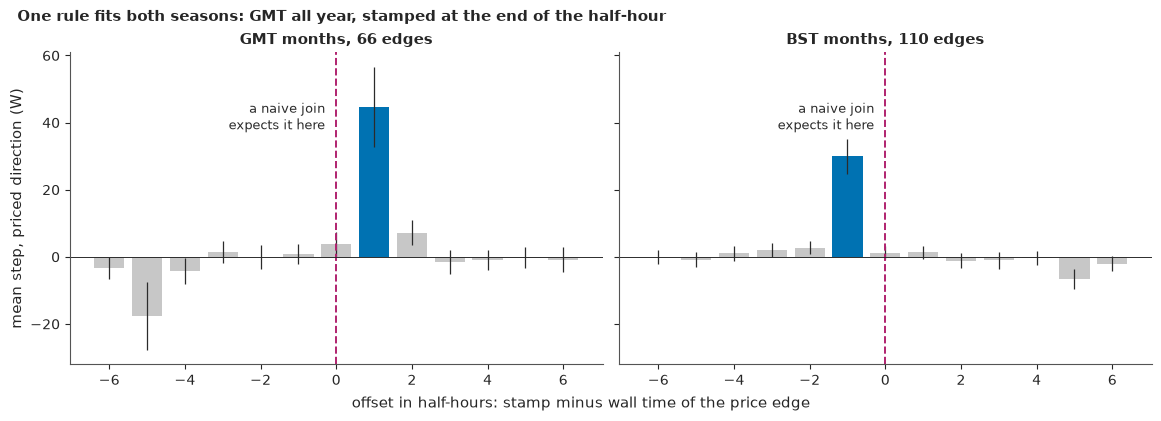

In [8]:
clock = store.load_json("pilot_clock")
cost = store.load_json("clock_cost")
fig, axes = plt.subplots(1, 2, figsize=(11.5, 4.1), sharey=True, layout="constrained")
for ax, key, title, predicted in zip(axes, ("gmt_both", "bst_both"), ("GMT months", "BST months"), (1, -1)):
    t = clock["tables"][key]
    offset, mean, se = np.array(t["offset"]), np.array(t["mean_w"]), np.array(t["se_w"])
    ax.bar(
        offset,
        mean,
        yerr=1.96 * se,
        width=0.8,
        color=[SF_C if o == predicted else "#c7c7c7" for o in offset],
        error_kw=dict(lw=0.9, ecolor=INK),
    )
    ax.axvline(0, color=DUD_C, lw=1.4, ls="--")
    ax.annotate(
        "a naive join\nexpects it here",
        (0, 38),
        xytext=(-8, 0),
        textcoords="offset points",
        ha="right",
        fontsize=9,
        color=INK,
    )
    ax.axhline(0, color=INK, lw=0.7)
    ax.set_title(f"{title}, {t['n_events'][6]} edges", fontsize=10.5)
    ax.set(xticks=offset[::2])
    ax.tick_params(labelsize=10)
axes[0].set_ylabel("mean step, priced direction (W)", fontsize=10.5)
fig.supxlabel("offset in half-hours: stamp minus wall time of the price edge", fontsize=10.5)
fig.suptitle(
    "One rule fits both seasons: GMT all year, stamped at the end of the half-hour", x=0.01, ha="left", fontsize=11
)
naive, fixed = cost["wall_start"], cost["gmt_end"]
print("Mean tariff-minus-flat response inside SF runs, price direction (W). A timing check, never an effect:")
print(
    pd.DataFrame(
        {
            "naive join": [naive["gmt"]["mean_w"], naive["bst"]["mean_w"]],
            "gmt_end": [fixed["gmt"]["mean_w"], fixed["bst"]["mean_w"]],
        },
        index=["GMT", "BST"],
    )
    .assign(lost=lambda d: 1 - d["naive join"] / d["gmt_end"])
    .round(3)
    .to_string()
)
print(f"Clear of the worse neighbour by {clock['gate_margin_se']} se; the gate asked for 3");

The step falls one slot after the edge in GMT months and one slot before it in BST months. Only one
convention predicts that pair. A naive join is 30 minutes out in **both** seasons, in opposite
directions, and it throws away about 12% of the response in each, with no error and no warning.
The smaller bars six slots from each peak, at -5 in GMT and +5 in BST, are probably the far edge of
3-hour events. That is an inference and was not tested.
The fix is one line of arithmetic, and it sits in the data script: every hour in this notebook is two
half-hours read in the meter's own frame, with wall time derived from it.

## 4. The fix: each home against itself, and the third failure

M1 is the published method's plain descendant. For home $h$ in hour $t$, in mean kW,

$$y_{ht} \sim \text{Normal}\Big(b_{h,s(t)} + \beta_h z_t + \sum_k \delta_{hk} X_{kt},\ \sigma_h^2\Big).$$

In words: a home's usual load at this hour and day type, plus how much of today's shared shock it
picks up, plus an effect for each kind of price event.

- **$s(t)$** has 48 levels: wall hour x weekday or weekend. This is where GMT meters meet wall-clock life.
- **$z_t$** is the flat homes' load against its own mean at that hour and day type.
- **$\delta_{hk}$** are 11 effects: SF High and SF Low by time band, and three CM terms. Hours next to
  an SF event stay in the baseline with no term of their own, so M1 does not measure load moved to
  those hours. Section 6 checks them once, on the fleet mean.
- **Priors** in kW: $b \sim N(0.4, 0.5)$, $\beta \sim N(1, 1)$, $\delta \sim N(0, 0.3)$. With $\sigma_h$
  plugged in, each home's posterior is a small dense solve, so a fleet costs seconds and no sampler.

What do those priors say about one hour? We draw from them before seeing any fit.

In [9]:
prior_rng = np.random.default_rng(RANDOM_SEED + 1)
prior_load = prior_rng.normal(0.4, 0.5, 4000) + prior_rng.normal(1, 1, 4000) * prior_rng.normal(0, 0.1, 4000)
prior_delta = prior_rng.normal(0, 0.3, 4000)
prior_view = pd.DataFrame(
    {
        "5%": np.quantile(1000 * np.c_[prior_load, prior_delta], 0.05, axis=0),
        "median": np.median(1000 * np.c_[prior_load, prior_delta], axis=0),
        "95%": np.quantile(1000 * np.c_[prior_load, prior_delta], 0.95, axis=0),
    },
    index=["usual load at one hour (W)", "effect of an event (W)"],
)
print(prior_view.round(0).to_string())
print(f"Prior share of hours with a negative usual load: {(prior_load < 0).mean():.0%}")
print(
    f"Fleet mean load in 2013: {1000 * np.nanmean(fleet_kw[in_2013]):.0f} W, evening {1000 * np.nanmean(fleet_kw[in_2013 & evening]):.0f} W"
)

                               5%  median     95%
usual load at one hour (W) -465.0   400.0  1292.0
effect of an event (W)     -489.0     1.0   481.0
Prior share of hours with a negative usual load: 22%
Fleet mean load in 2013: 393 W, evening 554 W


Wide, and deliberately so. The load prior allows some impossible negative hours, and the event prior
allows swings many times any published effect. With about 14,000 hours per home, neither prior
matters for a usual load, and a pooled event effect has 72 hours behind it. This matters only in
one place: an event cell has a handful of hours per home, so the home x event table uses a prior sd
of 5 kW. A first pilot run left the tighter prior on those cells, shrank them towards 0, and
understated how much event days differ. It was corrected, and no verdict changed.

Now M1, live, on the 200 homes in this repository.

In [10]:
def deviation(keep):
    """z[t]: the flat homes' load in kW, against its own mean at that wall hour and day type."""
    z = np.zeros(n_hours)
    for s in range(48):
        at = level == s
        z[at] = panel_kw[at] - panel_kw[at & keep].mean()
    return np.nan_to_num(z)


def month_band(keep):
    """One indicator per month x time band, for the post-hoc local baseline."""
    key = pd.factorize(pd.Series(gmt.strftime("%Y-%m")).astype(str) + band.astype(str))[0]
    used, column = np.unique(key[keep], return_inverse=True)
    row = np.flatnonzero(keep)
    return sparse.csr_matrix((np.ones(row.size), (row, column)), shape=(n_hours, used.size))


def design(keep, local=False):
    """Hours x columns for M1: 48 levels, z, 11 effects, and month x band terms if asked."""
    rows = np.arange(n_hours)
    on = effect >= 0
    parts = [
        sparse.csr_matrix((np.ones(n_hours), (rows, level)), shape=(n_hours, 48)),
        sparse.csr_matrix(deviation(keep)[:, None]),
        sparse.csr_matrix((np.ones(on.sum()), (rows[on], effect[on])), shape=(n_hours, 11)),
    ]
    if local:
        parts.append(month_band(keep))
    return sparse.hstack(parts, format="csr")


def m1(kw, keep, local=False):
    """Closed-form fleet: conjugate Gaussian with plug-in sigma, home by home. Effects in W."""
    x_all = design(keep, local)
    q = x_all.shape[1] - 60
    prior_mean = np.r_[np.full(48, 0.4), 1.0, np.zeros(11 + q)]
    prior_prec = 1 / np.r_[np.full(48, 0.5), 1.0, np.full(11, 0.3), np.full(q, 0.5)] ** 2
    out = {
        "mean": np.full((len(kw), 11), np.nan),
        "sd": np.full((len(kw), 11), np.nan),
        "sigma": np.full(len(kw), np.nan),
        "kurtosis": np.full(len(kw), np.nan),
    }
    for h, y in enumerate(kw):
        ok = np.isfinite(y) & keep
        x, target = x_all[ok], y[ok]
        gram, moment = (x.T @ x).toarray(), x.T @ target
        variance = target.var()
        for _ in range(2):  # plug-in sigma: two passes are enough at these lengths
            precision = gram / variance + np.diag(prior_prec)
            theta = np.linalg.solve(precision, moment / variance + prior_prec * prior_mean)
            residual = target - x @ theta
            variance = float(np.mean(residual**2))
        cov = np.linalg.inv(gram / variance + np.diag(prior_prec))
        out["mean"][h] = 1000 * theta[49:60]
        out["sd"][h] = 1000 * np.sqrt(np.diag(cov)[49:60])
        out["sigma"][h] = 1000 * np.sqrt(variance)
        out["kurtosis"][h] = stats.kurtosis(residual)
    return out


meter_wh = meter_file["wh"].astype(float)
meter_wh[meter_file["wh"] == 65535] = np.nan
meters = meter_wh / 1000  # Wh in an hour is mean W, so this is mean kW
started = time.perf_counter()
with stage("M1, 200 homes, three baselines"):
    live = {
        "whole window": m1(meters, usable),
        "2013 only": m1(meters, usable & in_2013),
        "2013, month x band": m1(meters, usable & in_2013, local=True),
    }
pooled = store.load_json("pilot_placebo_benchmark")
names = {"whole window": "p6", "2013 only": "p6_2013only", "2013, month x band": "p6_local_2013only"}
compare = {}
for name, fit in live.items():
    for band_name in GATE_BANDS:
        k = EFFECTS.index(band_name)
        compare[(name, band_name)] = {
            "200 homes, live": fit["mean"][:, k].mean(),
            "se between homes": fit["mean"][:, k].std(ddof=1) / np.sqrt(len(meters)),
            "1,088 homes, stored": pooled[names[name]]["bands"][band_name]["mean_w"],
        }
print(f"Three fleets of {len(meters)} homes in {time.perf_counter() - started:.1f} s, no sampler")
print(pd.DataFrame(compare).T.round(1).to_string())
print(
    f"\nResiduals: excess kurtosis across homes, median {np.median(live['whole window']['kurtosis']):.1f} "
    f"(10-90%: {np.quantile(live['whole window']['kurtosis'], 0.1):.1f} to "
    f"{np.quantile(live['whole window']['kurtosis'], 0.9):.1f}); a Gaussian has 0"
)

Three fleets of 200 homes in 1.0 s, no sampler
                                    200 homes, live  se between homes  1,088 homes, stored
whole window       SF High evening            -45.0               5.9                -41.1
                   SF Low evening              38.6               7.8                 34.1
                   CM High evening            -60.0               8.9                -48.4
2013 only          SF High evening            -32.8               5.2                -31.6
                   SF Low evening              50.6               7.9                 43.7
                   CM High evening            -47.4               8.0                -39.5
2013, month x band SF High evening            -32.1               5.1                -29.4
                   SF Low evening              51.4               7.7                 42.7
                   CM High evening            -54.1               9.1                -44.2

Residuals: excess kurtosis across homes, m

About a second, with no sampler. The 200 homes land within about 1.3 standard errors of the fleet in
every cell, with a standard error of about 5-9 W. They are a repository-sized check and not the
estimate. The noise is far from Gaussian, as the kurtosis shows. A mean does not need Gaussian noise
to be unbiased, and section 5 shows what happens when a model tries to respect those tails. A home's
posterior sd is therefore not trusted here. Standard errors come from the spread between homes and
between events.

The fleet results in the rest of the notebook were fitted the same way, by the data script, on all
1,088 tariff homes with at least half of 2013. That took 1-6 s per run in the pilot. The stored table
has one term per event cell, and its SF columns come from fits with the CM hours left out.

### Three checks, read before any delivery number

Their gates were fixed in writing before they ran.

**Is the calendar really random?** The seed and rule were never published, so this is approximate.
Flat homes never saw a price, so their evening load on SF days should look like any other day, net
of month and day type. We shuffled the SF days 20,000 times under a weekly limit.

In [11]:
balance = store.load_json("pilot_balance")
rows = {
    name: balance["sf_all"][key]
    for name, key in (("All 90 SF days", "all"), ("GMT months", "gmt"), ("BST months", "bst"))
}
rows["The 15 evening High days (not gated)"] = balance["sf_evening_high"]["all"]
print(
    pd.DataFrame(rows)
    .T[["obs_w", "null_sd", "z"]]
    .rename(columns={"obs_w": "SF minus default (W)", "null_sd": "null sd (W)"})
    .round(2)
    .to_string()
)

                                      SF minus default (W)  null sd (W)     z
All 90 SF days                                       -2.04         4.10 -0.49
GMT months                                           -7.22         7.09 -0.98
BST months                                            1.30         4.98  0.23
The 15 evening High days (not gated)                 10.25         8.87  1.18


In [12]:
placebo = pooled["p5"]["bands"]
no_dud = pooled["p5_no28dec"]["bands"]
placebo_view = pd.DataFrame(
    {
        b: {
            "events": placebo[b]["events"],
            "mean (W)": placebo[b]["mean_w"],
            "se homes": placebo[b]["se_home_w"],
            "se events": placebo[b]["se_event_w"],
            "without the shifted 28 Dec": no_dud[b]["mean_w"],
        }
        for b in GATE_BANDS
    }
).T
print(
    "Placebo: the 2013 calendar moved back 364 days, Jul-Dec 2012, no prices existed. Gate: |mean| <= 10 W, se <= 5 W"
)
print(placebo_view.round(1).to_string())
print(
    f"Homes: {pooled['p5']['homes']}. Passes: {pooled['p5_passes']}. Over the 25 W line that ends the estimate: {pooled['p5_over25']}"
)
shifted = next(c for c in pooled["p5"]["cells"] if c["day"] == DUD_DAY and c["effect"] == "SF High evening")
dud_column = placebo_cells.index[(placebo_cells["day"] == DUD_DAY) & (placebo_cells["effect"] == "SF High evening")][0]
dud_se = np.nanstd(placebo_table[:, dud_column], ddof=1) / np.sqrt(np.isfinite(placebo_table[:, dud_column]).sum())
print(
    f"The placebo cell for 29 Dec 2012 alone, the day that lines up with 28 Dec 2013: {shifted['w']:+.1f} W (se {dud_se:.1f}), no price at all"
)
print(
    "All four SF High placebo cells:",
    [f"{c['w']:+.1f} W" for c in pooled["p5"]["cells"] if c["effect"] == "SF High evening"],
)
print(
    f"Post-hoc, not a rescue: with month x band terms CM's placebo is {pooled['p5_local']['bands']['CM High evening']['mean_w']:+.1f} W, "
    f"SF High evening {pooled['p5_local']['bands']['SF High evening']['mean_w']:+.1f} W"
)

Placebo: the 2013 calendar moved back 364 days, Jul-Dec 2012, no prices existed. Gate: |mean| <= 10 W, se <= 5 W
                 events  mean (W)  se homes  se events  without the shifted 28 Dec
SF High evening     4.0      -6.1       4.4       10.6                         1.1
SF Low evening     10.0      -0.2       3.1        2.7                        -0.2
CM High evening     5.0      13.2       4.2        2.1                        12.9
Homes: 963. Passes: False. Over the 25 W line that ends the estimate: False
The placebo cell for 29 Dec 2012 alone, the day that lines up with 28 Dec 2013: -27.7 W (se 12.5), no price at all
All four SF High placebo cells: ['+2.0 W', '+10.5 W', '-4.4 W', '-27.7 W']
Post-hoc, not a rescue: with month x band terms CM's placebo is +4.9 W, SF High evening -6.4 W


Benchmark on 1,088 homes (gate: CM -70 to -30 W, SF -50 to -15 W). Passes: True
                               SF High evening  SF Low evening  CM High evening
Whole window (the plan)                  -41.1            34.1            -48.4
Same, without 28 Dec                     -43.9            34.1            -48.3
2013 only                                -31.6            43.7            -39.5
2013, month x band (post-hoc)            -29.4            42.7            -44.2
Same, without 28 Dec                     -31.8            42.7            -44.2

SF High evening, hour-weighted, resampling the 15 events (the calendar's sample, not the homes'):
  2013, month x band: -29.2 W, 90% interval -36.3 to -22.7 W
  whole window: -41.6 W, 90% interval -47.3 to -35.4 W


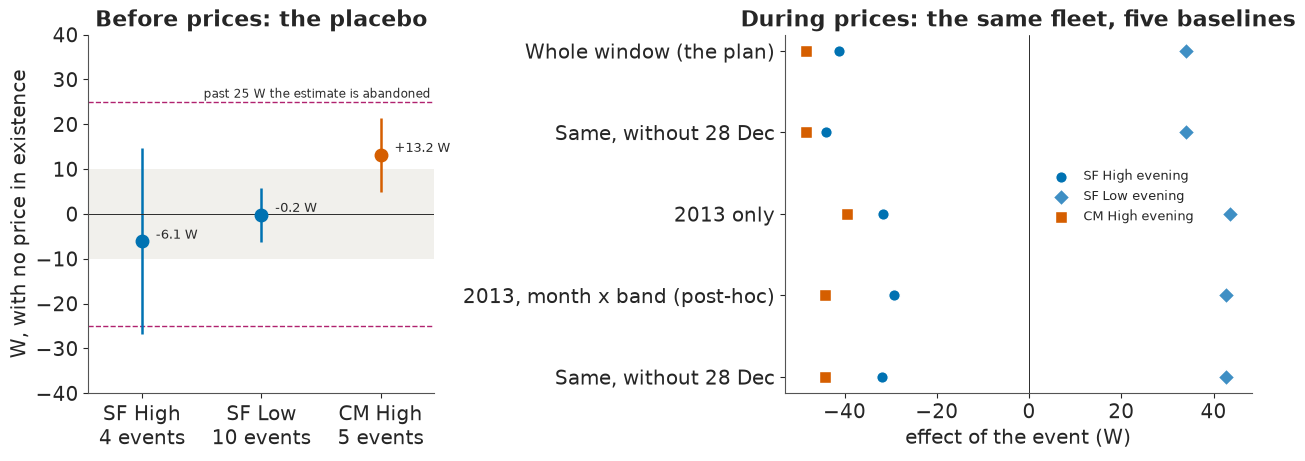

In [13]:
baselines = {
    "Whole window (the plan)": "p6",
    "Same, without 28 Dec": "p6_no28dec",
    "2013 only": "p6_2013only",
    "2013, month x band (post-hoc)": "p6_local_2013only",
    "Same, without 28 Dec ": "p6_local_2013_no28dec",
}
window = pd.DataFrame({k: {b: pooled[v]["bands"][b]["mean_w"] for b in GATE_BANDS} for k, v in baselines.items()}).T
print(
    f"Benchmark on {pooled['p6']['homes']:,} homes (gate: CM -70 to -30 W, SF -50 to -15 W). Passes: {pooled['p6_passes']}"
)
print(window.round(1).to_string())

sf_high = cells[cells["effect"] == "SF High evening"]
event_hours_w = sf_high["hours"].to_numpy(float)
picks = np.random.default_rng(RANDOM_SEED + 5).integers(0, len(sf_high), (20_000, len(sf_high)))
print("\nSF High evening, hour-weighted, resampling the 15 events (the calendar's sample, not the homes'):")
for name, key in (("2013, month x band", "local"), ("whole window", "plan")):
    event_w = np.nanmean(home_tables[key][:, sf_high.index], axis=0)
    resampled = (event_w[picks] * event_hours_w[picks]).sum(axis=1) / event_hours_w[picks].sum(axis=1)
    print(
        f"  {name}: {np.average(event_w, weights=event_hours_w):.1f} W, 90% interval "
        f"{np.quantile(resampled, 0.05):.1f} to {np.quantile(resampled, 0.95):.1f} W"
    )

fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.5), width_ratios=(1, 1.35), layout="constrained")
ax = axes[0]
ax.axhspan(-10, 10, color="#f1f0ec", lw=0, label="gate: within 10 W")
for line in (-25, 25):
    ax.axhline(line, color=DUD_C, lw=1, ls="--")
ax.annotate(
    "past 25 W the estimate is abandoned",
    (2.42, 25),
    xytext=(0, 3),
    textcoords="offset points",
    ha="right",
    fontsize=8.5,
    color=INK,
)
for i, b in enumerate(GATE_BANDS):
    colour = CM_C if b.startswith("CM") else SF_C
    r = placebo[b]
    ax.errorbar(
        i, r["mean_w"], 1.96 * max(r["se_home_w"], r["se_event_w"]), fmt="o", ms=9, color=colour, capsize=0, lw=1.8
    )
    ax.annotate(
        f"{r['mean_w']:+.1f} W", (i, r["mean_w"]), xytext=(10, 2), textcoords="offset points", fontsize=9, color=INK
    )
ax.axhline(0, color=INK, lw=0.7)
ax.set_xticks(range(3), ["SF High\n4 events", "SF Low\n10 events", "CM High\n5 events"])
ax.set(xlim=(-0.45, 2.45), ylim=(-40, 40), ylabel="W, with no price in existence", title="Before prices: the placebo")
ax = axes[1]
y = np.arange(len(window))[::-1]
for b, colour, marker in zip(GATE_BANDS, (SF_C, SKY, CM_C), ("o", "D", "s")):
    ax.scatter(window[b], y, s=70, color=colour, marker=marker, edgecolor="w", lw=1, zorder=3, label=b)
ax.axvline(0, color=INK, lw=0.7)
ax.set_yticks(y, [k.strip() for k in window.index])
ax.set(xlabel="effect of the event (W)", title="During prices: the same fleet, five baselines")
ax.legend(loc="center", fontsize=9, bbox_to_anchor=(0.72, 0.55));

In [14]:
def fleet_fit(keep):
    """The fleet's mean load against M1's baseline, fitted to default hours inside `keep`, in W."""
    default_hours = keep & usable & (effect < 0)
    levels_x = sparse.csr_matrix((np.ones(n_hours), (np.arange(n_hours), level)), shape=(n_hours, 48))
    fleet_x = sparse.hstack(
        [levels_x, sparse.csr_matrix(deviation(keep & usable)[:, None]), month_band(keep)], format="csr"
    )
    solution = sparse.linalg.lsqr(fleet_x[default_hours], fleet_kw[default_hours], atol=1e-9, btol=1e-9, iter_lim=4000)[0]
    return 1000 * (fleet_kw - fleet_x @ solution)


whole_response = fleet_fit(np.ones(n_hours, dtype=bool))
forward = {}
for day in ("2013-02-11", "2013-02-27"):
    event = sf_high[sf_high["day"] == day].iloc[0]
    moved_day = (pd.Timestamp(day) + pd.Timedelta(days=364)).strftime("%Y-%m-%d")
    moved_hours = (
        (trial_day == moved_day) & (hour_of_day >= event["start_hour"]) & (hour_of_day < event["start_hour"] + event["event_hours"])
    )
    forward[f"{day} moved to {moved_day}"] = np.nanmean(whole_response[moved_hours])
late_quiet = quiet & after_trial
print("The February evenings moved forward 364 days, prices over, fleet mean, W:", {k: round(v, 1) for k, v in forward.items()})
print(
    "Spread of a Jan-Feb 2014 default evening, same fit:",
    f"{pd.Series(whole_response[late_quiet]).groupby(trial_day[late_quiet]).mean().std():.1f} W",
)

The February evenings moved forward 364 days, prices over, fleet mean, W: {'2013-02-11 moved to 2014-02-10': np.float64(17.9), '2013-02-27 moved to 2014-02-26': np.float64(11.7)}
Spread of a Jan-Feb 2014 default evening, same fit: 9.4 W


Three results, one of them bad news.

**Balance passed.** Flat homes' evening load on SF days looks like any other day's, in both seasons.
That test has no weather data, so it can only see what flat load shows. Under a Monday-to-Sunday week
the "limit of 3 events a week" does not hold, so the limit we shuffled under barely binds. The word
"randomised" stays.

**The benchmark passed.** The fleet reproduces the published ranges on peak days and on SF evenings.

**The placebo failed, and this is the third failure.** No price existed in 2012, so anything here is
bias or chance. The peak-day placebo is +13.2 W, 3 W over the limit. SF High has an se of 10.6 W on
4 events, twice the limit. No band passed 25 W, so the notebook stays a delivery estimate, but the
written action now applies: **report only the SF within-home range**. CM stays on the page, labelled,
and it does not carry an estimate. Post-hoc month x band terms take CM's placebo down to about +5 W,
which suggests one `beta` across all hours misses the winter evening rise. It does not un-fail a gate.

Note the Christmas cell. The single evening that lines up with 28 December has a placebo of about
-28 W (se about 12) with no price at all. That is one cell at about 2.2 se, and the other three SF
High placebo cells are small, so it does not show that Christmas week is loud: section 6 finds
late-December evenings about as noisy as any others. It only stops us reading 28 December 2013's
near-zero as proof that the signal was not sent.

The placebo used four SF High dates, and the two February evenings that carry the winter mean were
not among them, because 2012 has no February here. The last cell moves them forward into 2014, after
the prices ended. Both land on the side of no response, within about 2 sd of an ordinary evening, so
no sign of a false cut there. That check was added after the fact and uses the fleet mean only.

**The window matters.** Using pre-trial data pulls every evening effect about 10 W more negative, in
High and in Low alike. A real response to a High price would not push Low the same way. It looks
like a 2013 level shift, the same one that widened the gap in section 2. On SF High evenings that
shift is about 15 W in summer and about 3 W in winter, so the gap between the baselines is mostly a
summer issue. The estimand compares a home with ordinary days of the trial, which favours the 2013
window. That argument came after the placebo, so the whole-window figure stays in the range, because
the plan fixed it first. The table above is the stored pilot, and its fits still hold CM hours, as the
benchmark gate needs. The range is taken from the home x event table instead, the hour-weighted lines
printed under it, where CM hours are out of every SF figure. **SF evening range: about -29 to -42 W.**
That range has no sampling uncertainty in it. Resampling the 15 events gives about -23 to -36 W around
one end and about -35 to -47 W around the other.

## 5. The fourth failure: the robust model

Residuals with an excess kurtosis near 12 are the textbook case for a Student-t likelihood, and the
original plan was thousands of them. M2 keeps M1's structure and changes one line:

$$y_{ht} \sim \text{StudentT}\big(\nu_h,\ b_{h,s(t)} + \beta_h z_t + \sum_k \delta_{hk} X_{kt},\ \sigma_h\big),
\qquad \nu_h = 2 + \text{Gamma}(2, 0.1).$$

The floor of 2 keeps the variance finite. The prior puts $\nu$ around 20, so the data have to argue for
heavy tails. We fit every tenth home of the 200, 20 in all, with one compiled model and `with_data`.

In [15]:
with pm.Model() as m2:
    y_data = pm.Data("y", np.zeros(200))
    x_data = pm.Data("X", np.zeros((200, 11)))
    z_data = pm.Data("z", np.zeros(200))
    s_data = pm.Data("s", np.zeros(200, dtype="int64"))
    b = pm.Normal("b", 0.4, 0.5, shape=48)
    beta = pm.Normal("beta", 1, 1)
    delta = pm.Normal("delta", 0, 0.3, shape=11)
    sigma = pm.LogNormal("sigma", np.log(0.3), 0.7)
    nu_extra = pm.Gamma("nu_extra", 2, 0.1)
    location = b[s_data] + beta * z_data + x_data @ delta
    pm.StudentT("obs", nu=2 + nu_extra, mu=location, sigma=sigma, observed=y_data, shape=location.shape)

with stage("M2, compile"):
    compiled = nutpie.compile_pymc_model(m2)

z_all = deviation(usable)
effect_hours = np.zeros((n_hours, 11))
effect_hours[np.flatnonzero(effect >= 0), effect[effect >= 0]] = 1.0
student_rows = []
with stage("M2, 20 homes"):
    for i, h in enumerate(range(0, len(meters), 10)):
        ok = np.isfinite(meters[h]) & usable
        started = time.perf_counter()
        trace = nutpie.sample(
            compiled.with_data(y=meters[h, ok], X=effect_hours[ok], z=z_all[ok], s=level[ok].astype("int64")),
            chains=4,
            tune=500,
            draws=500,
            cores=CHAINS_AT_ONCE,
            seed=RANDOM_SEED + i,
            progress_bar=False,
            save_warmup=False,
            store_mass_matrix=False,
            store_gradient=False,
            store_unconstrained=False,
        )
        post = trace.posterior.to_dataset()
        hat = az.rhat(post)
        hat = hat.to_dataset() if hasattr(hat, "to_dataset") else hat
        ess = az.ess(post)
        ess = ess.to_dataset() if hasattr(ess, "to_dataset") else ess
        student_rows.append(
            {
                "home": int(meter_file["homes"][h]),
                "row": h,
                "seconds": time.perf_counter() - started,
                "max r_hat": max(float(np.nanmax(hat[v].values)) for v in hat.data_vars),
                "min ESS": min(float(np.nanmin(ess[v].values)) for v in ess.data_vars),
                "divergences": int(trace.sample_stats["diverging"].values.sum()),
                "nu": 2 + float(post["nu_extra"].median()),
                **{
                    b_name: 1000 * float(post["delta"].mean(("chain", "draw")).values[EFFECTS.index(b_name)])
                    for b_name in GATE_BANDS
                },
            }
        )
student = pd.DataFrame(student_rows)
print(
    student[["seconds", "max r_hat", "min ESS", "divergences", "nu"]]
    .describe()
    .loc[["min", "50%", "max"]]
    .round(3)
    .to_string()
)
print(
    f"Homes at max r_hat <= 1.01: {(student['max r_hat'] <= 1.01).sum()} of {len(student)}; <= 1.02: {(student['max r_hat'] <= 1.02).sum()}"
)
print(
    "Worst of the 20:",
    student.sort_values("max r_hat")
    .iloc[-1][["home", "max r_hat", "min ESS", "divergences", "seconds"]]
    .round(2)
    .to_dict(),
)
paired = {
    b_name: live["whole window"]["mean"][student["row"].to_numpy(), EFFECTS.index(b_name)]
    - student[b_name].to_numpy()
    for b_name in GATE_BANDS
}
print(
    pd.DataFrame(
        {
            b_name: {
                "M1 mean of 20 homes (W)": live["whole window"]["mean"][
                    student["row"].to_numpy(), EFFECTS.index(b_name)
                ].mean(),
                "M2 mean of 20 homes (W)": student[b_name].mean(),
                "paired se (W)": paired[b_name].std(ddof=1) / np.sqrt(len(student)),
            }
            for b_name in GATE_BANDS
        }
    )
    .round(1)
    .to_string()
)

fit_pilot, location_pilot = store.load_json("pilot_fit"), store.load_json("pilot_mean_location")
print(
    f"\nStored, 100 homes: median {fit_pilot['median_s']:.1f} s a fit, {fit_pilot['total_div']} divergences, "
    f"{fit_pilot['rhat_le_1.01']} homes at r_hat <= 1.01 and {fit_pilot['rhat_le_1.02']} at 1.02, "
    f"median nu {fit_pilot['nu_median']:.3f}. Worst homes:"
)
print(pd.DataFrame(fit_pilot["worst"])[["home", "rhat", "nu", "div"]].head(3).to_string(index=False))

     seconds  max r_hat   min ESS  divergences     nu
min    4.566      1.007     6.157          0.0  2.001
50%    5.210      1.011  2855.401          0.0  2.003
max   24.476      1.734  3434.193          0.0  2.365
Homes at max r_hat <= 1.01: 9 of 20; <= 1.02: 18
Worst of the 20: {'home': 1704.0, 'max r_hat': 1.73, 'min ESS': 6.16, 'divergences': 0.0, 'seconds': 5.15}
                         SF High evening  SF Low evening  CM High evening
M1 mean of 20 homes (W)            -62.3            49.9            -85.9
M2 mean of 20 homes (W)            -39.1            -4.4            -26.2
paired se (W)                        7.3            18.3             15.0

Stored, 100 homes: median 10.1 s a fit, 0 divergences, 40 homes at r_hat <= 1.01 and 97 at 1.02, median nu 2.005. Worst homes:
 home   rhat  nu  div
 1704 1.7357 2.0    0
 3047 1.7326 2.0    0
 4687 1.5277 2.0    0


Two things have gone wrong, and the sampler reports neither as a failure.

`nu` sits on its floor: median 2.003, highest 2.37, the same as in the 100 stored fits. The likelihood
has run out of room. Hourly load is more heavy-tailed than this model allows.

Then there is mixing. There are no divergences at all. Yet here 9 of 20 homes reach the r_hat gate of
1.01, and in the stored 100 homes 40 did, with 97 reaching 1.02. Most misses are too few draws: six
homes rerun at 2,000 draws came out clean. Three homes (1704, 3047, 4687) are a different story, and
home 494 did the same on one seed of two, taking 260 s. Homes 1704 and 4687 are both in this run's 20,
at r_hat 1.73 and 1.53. The worst has a minimum ESS of 6, and still no divergence. These chains sit
in different modes, mostly of `b` and on some homes of `sigma`, and longer runs did not cure it. We
did not establish why. Repeated quantised readings at a near-constant base load are a guess.

Those are diagnostics. The serious problem is the answer. M1 and M2 disagree in the bottom table,
and M2's figures are the smaller ones in all three bands. Where does an event take its watts from?
Take the 200 homes' hours during an evening event and compare them with the same homes at the same
wall hour and day type on nearby default days, one quantile at a time.

                                  10%   30%   50%   70%   80%   85%   90%    95%
SF High evening (W)               2.3  -5.7 -15.2 -14.4 -27.4 -59.9 -65.9 -135.8
no-price calendars, mean (W)      6.1   4.1   5.9   5.3   4.9  -0.6 -14.6  -36.6
SF minus no-price (W)            -3.8  -9.9 -21.1 -19.7 -32.3 -59.3 -51.3  -99.1
SF, percent of that quantile      1.2  -1.8  -3.5  -2.4  -3.7  -6.9  -6.4  -10.4
CM High evening (W)               5.4  -1.8  -8.2 -45.8 -48.0 -50.8 -85.4 -137.2
CM no-price calendars, mean (W)  18.4  22.1  19.5  18.1  19.8  21.5  16.8   -3.1
Mean hour: SF -23 W (-4.3%), CM -27 W
No-price calendars at the 95th percentile, 5-95%: -107 to 11 W; at the median -17 to 24 W


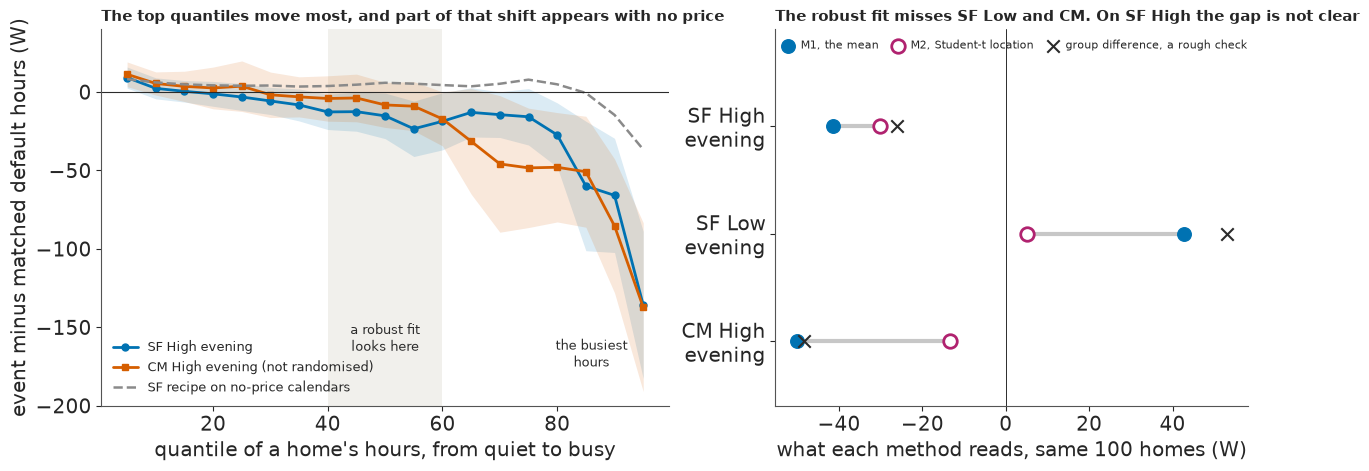

In [16]:
QUANTILES = np.arange(0.05, 0.96, 0.05)


def shift_gaps(hours_on):
    """These hours minus matched default hours within 28 days, by quantile of each home's own hours, W."""
    clean = (effect < 0) & usable & in_2013
    matched = []
    for t in hours_on:
        window_hours = np.arange(max(t - 672, 0), min(t + 672, n_hours))
        matched.append(window_hours[clean[window_hours] & (level[window_hours] == level[t])])
    matched = np.concatenate(matched)
    usual = np.nanquantile(meters[:, matched], QUANTILES, axis=1)
    gaps = np.nanquantile(meters[:, hours_on], QUANTILES, axis=1) - usual
    mean_gap = np.nanmean(meters[:, hours_on], axis=1) - np.nanmean(meters[:, matched], axis=1)
    return 1000 * gaps, 1000 * usual, 1000 * mean_gap, 1000 * np.nanmean(meters[:, matched], axis=1)


def shift_function(which):
    """The shift across 200 homes: mean gap by quantile, its se, the mean hour, and the gap in percent."""
    gaps, usual, mean_gap, mean_usual = shift_gaps(np.flatnonzero((effect == EFFECTS.index(which)) & in_2013))
    return (
        gaps.mean(axis=1),
        gaps.std(axis=1, ddof=1) / np.sqrt(len(meters)),
        mean_gap.mean(),
        100 * gaps.mean(axis=1) / usual.mean(axis=1),
        100 * mean_gap.mean() / mean_usual.mean(),
    )


def no_price_shifts(which, draws=40):
    """The same recipe on calendars with no price: each event moved whole weeks onto default hours."""
    hours_on = np.flatnonzero((effect == EFFECTS.index(which)) & in_2013)
    clean = (effect < 0) & usable & in_2013
    move_rng = np.random.default_rng(RANDOM_SEED + 4)
    options = []
    for day in np.unique(trial_day[hours_on]):
        block = hours_on[trial_day[hours_on] == day]
        moves = [block + 168 * w for w in range(-6, 7) if w and (block + 168 * w).max() < n_hours]
        options.append([m for m in moves if clean[m].all()])
    return np.array(
        [
            shift_gaps(np.concatenate([o[move_rng.integers(len(o))] for o in options]))[0].mean(axis=1)
            for _ in range(draws)
        ]
    )


q = QUANTILES
shift_sf, shift_se, shift_mean, percent_sf, percent_mean = shift_function("SF High evening")
shift_cm, shift_cm_se, cm_mean, percent_cm, _ = shift_function("CM High evening")
control_sf, control_cm = no_price_shifts("SF High evening"), no_price_shifts("CM High evening")
print(
    pd.DataFrame(
        {
            "SF High evening (W)": shift_sf,
            "no-price calendars, mean (W)": control_sf.mean(axis=0),
            "SF minus no-price (W)": shift_sf - control_sf.mean(axis=0),
            "SF, percent of that quantile": percent_sf,
            "CM High evening (W)": shift_cm,
            "CM no-price calendars, mean (W)": control_cm.mean(axis=0),
        },
        index=[f"{p:.0%}" for p in q],
    )
    .T.round(1)
    .iloc[:, [1, 5, 9, 13, 15, 16, 17, 18]]
    .to_string()
)
print(f"Mean hour: SF {shift_mean:.0f} W ({percent_mean:.1f}%), CM {cm_mean:.0f} W")
print(
    f"No-price calendars at the 95th percentile, 5-95%: {np.quantile(control_sf[:, -1], 0.05):.0f} to "
    f"{np.quantile(control_sf[:, -1], 0.95):.0f} W; at the median {np.quantile(control_sf[:, 9], 0.05):.0f} to "
    f"{np.quantile(control_sf[:, 9], 0.95):.0f} W"
)

fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.6), width_ratios=(1.2, 1), layout="constrained")
ax = axes[0]
for values, se, colour, label, marker in (
    (shift_sf, shift_se, SF_C, "SF High evening", "o"),
    (shift_cm, shift_cm_se, CM_C, "CM High evening (not randomised)", "s"),
):
    ax.fill_between(q * 100, values - 1.96 * se, values + 1.96 * se, color=colour, alpha=0.14, lw=0)
    ax.plot(q * 100, values, color=colour, lw=2, marker=marker, ms=5, label=label)
ax.plot(q * 100, control_sf.mean(axis=0), color=MUTED, lw=1.8, ls="--", label="SF recipe on no-price calendars")
ax.axhline(0, color=INK, lw=0.8)
ax.axvspan(40, 60, color="#f1f0ec", lw=0, zorder=0)
ax.annotate("a robust fit\nlooks here", (50, -165), ha="center", fontsize=9.5, color=INK)
ax.annotate("the busiest\nhours", (86, -175), ha="center", fontsize=9.5, color=INK)
ax.set(
    xlabel="quantile of a home's hours, from quiet to busy",
    ylabel="event minus matched default hours (W)",
    ylim=(-200, 40),
)
ax.legend(loc="lower left", fontsize=9)
ax.set_title("The top quantiles move most, and part of that shift appears with no price", loc="left", fontsize=11)

ax = axes[1]
order = list(GATE_BANDS)
y = np.arange(3)[::-1]
for yi, b_name in zip(y, order):
    r = location_pilot["bands"][b_name]
    ax.plot([r["m1"], r["m2"]], [yi, yi], color="#c7c7c7", lw=3, zorder=1)
    ax.scatter(r["m1"], yi, s=95, color=SF_C, zorder=3, label="M1, the mean" if yi == 2 else None)
    ax.scatter(
        r["m2"],
        yi,
        s=95,
        facecolor="w",
        edgecolor=DUD_C,
        lw=2,
        zorder=3,
        label="M2, Student-t location" if yi == 2 else None,
    )
    ax.scatter(r["gd"], yi, s=80, marker="x", color=INK, zorder=4, label="group difference, a rough check" if yi == 2 else None)
ax.axvline(0, color=INK, lw=0.7)
ax.set_yticks(y, ["SF High\nevening", "SF Low\nevening", "CM High\nevening"])
ax.set(xlabel="what each method reads, same 100 homes (W)", ylim=(-0.6, 2.9))
ax.legend(loc="upper center", ncols=3, fontsize=8.2, bbox_to_anchor=(0.5, 1.0), handletextpad=0.1, columnspacing=0.7)
ax.set_title("The robust fit misses SF Low and CM. On SF High the gap is not clear", loc="left", fontsize=11);

The left panel shows where the shift is, and the dashed line shows how far to trust it. On SF evenings
the 30th percentile reads about 6 W lower, the median about 15 W, the 90th about 66 W and the 95th
about 136 W. But the recipe compares the quantiles of 72 hours with those of a much larger set of hours,
and that is biased even with no price. Move the same events by whole weeks onto default hours and it
reads about +6 W at the median and about -37 W at the 95th, and those 40 calendars spread widely.
Net of that control the median is about -21 W and the 95th about -99 W. So the direction survives,
and the middle hours move about as much as the mean hour, -23 W. In percent of the matched quantile the
SF shift is -3.5% at the median and -10.4% at the 95th, against -4.3% for the mean hour, so part of
the rise in watts is simply that busy hours are bigger. The busiest hours are when people cook and
wash, so moved or skipped appliance use is the likely reading, but the data have no appliance column.
That part is inference. These compare distributions, not paired hours. The recipe also has no shared-shock
term, so its mean hour reads less than M1's on the same homes, about -32 W and -47 to -54 W. The CM days
were placed as well, so the CM curve is a description, not an effect.

Now the right panel. A Student-t location follows the typical hour and discounts busy hours as
outliers. It is not a mean. On the 100 stored homes it sees about a quarter of the peak-day cut and an
eighth of the SF Low rise. Pilot P10 asked the location and the group difference to agree with the
mean within 20% in all three bands. The location missed in all three, and the group difference in two,
passing on CM, so the gate failed in every band. The group difference is imprecise on 100 homes,
so the firm part is M2 against M1, on SF Low and on the placed CM band.

The randomised High band does not show it so clearly. M2 reads about -30 W against M1's -41 W there, a
gap of about 1.7 paired se. That sits inside this notebook's own baseline range, and the group
difference, at -26 W, is closer to M2. This run's 20 homes lean the same way in all three bands, with
SF Low's M2 unstable in sign on so few homes (-4 W).

This was the plan's likely failure. It predicted that the Student-t fleet would be decoration. It did
worse on SF Low and on CM, where a sum built on it would have **understated the change**. **The fix** is
to ask what adds up at a substation. It is the sum of means, in kilowatts, so M1 carries the kW figures
on that argument, not because M2 was shown wrong on the headline band. Student-t would be kept only for
spread, which this notebook does not report. The two-stage pooling models in the plan are built on M2's
draws, so they inherit this and are not reported as results.

## 6. Every evening counts

Here are the 15 randomised evening events, one panel each, as the whole fleet's response hour by
hour against a baseline fitted to default hours of 2013. These are group means of 1,088 homes.

Default-hour fit: residual sd 12.4 W per hour


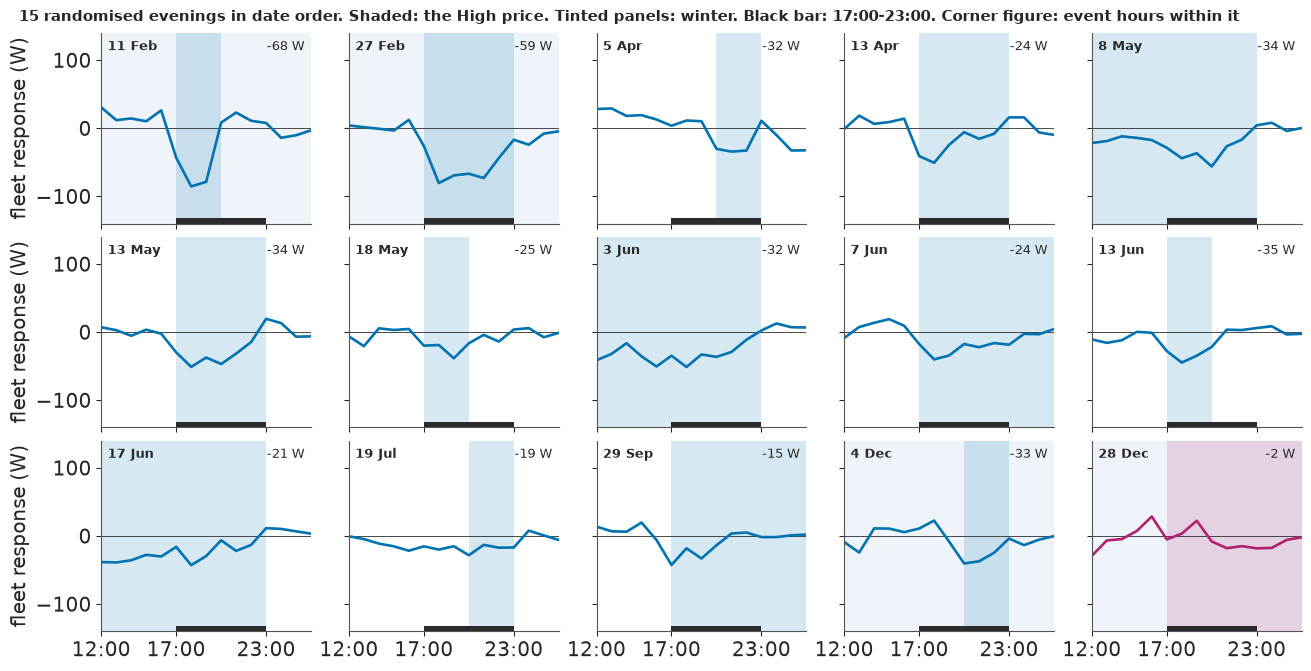

In [17]:
with stage("Fleet curves"):
    clean_hours = usable & in_2013 & (effect < 0)
    fleet_response = fleet_fit(in_2013)
print(f"Default-hour fit: residual sd {np.nanstd(fleet_response[clean_hours]):.1f} W per hour")

evening_events = cells[cells["effect"] == "SF High evening"].sort_values("day")
local_means = pd.Series(
    np.nanmean(home_tables["local"][:, evening_events.index], axis=0), index=evening_events["day"]
)
fig, axes = plt.subplots(3, 5, figsize=(13, 6.6), sharex=True, sharey=True, layout="constrained")
for ax, (_, event) in zip(axes.flat, evening_events.iterrows()):
    on_day = trial_day == event["day"]
    t = hour_of_day[on_day] + np.where(hour_of_day[on_day] < 5, 24, 0)
    order = np.argsort(t)
    show = (t[order] >= 12) & (t[order] <= 26)
    start, stop = event["start_hour"], event["start_hour"] + event["event_hours"]
    colour = DUD_C if event["day"] == DUD_DAY else SF_C
    is_winter = event["season"] == "gmt"
    ax.set_facecolor("#eef4f9" if is_winter else "#ffffff")
    ax.axvspan(max(start, 12), min(stop, 26), color=colour, alpha=0.16, lw=0)
    ax.axvspan(17, 23, ymin=0, ymax=0.03, color=INK, lw=0)
    ax.axhline(0, color=INK, lw=0.6)
    ax.plot(t[order][show], fleet_response[on_day][order][show], color=colour, lw=1.9)
    ax.text(
        0.03,
        0.91,
        f"{pd.Timestamp(event['day']):%-d %b}",
        transform=ax.transAxes,
        fontsize=9.5,
        weight="bold",
        color=INK,
    )
    ax.text(
        0.97, 0.91, f"{local_means[event['day']]:+.0f} W", transform=ax.transAxes, ha="right", fontsize=9.5, color=INK
    )
axes[0, 0].set(ylim=(-140, 140), xlim=(12, 26), xticks=[12, 17, 23], xticklabels=["12:00", "17:00", "23:00"])
for ax in axes[:, 0]:
    ax.set_ylabel("fleet response (W)")
fig.suptitle(
    "15 randomised evenings in date order. Shaded: the High price. Tinted panels: winter. Black bar: 17:00-23:00. Corner figure: event hours within it",
    x=0.01,
    ha="left",
    fontsize=11,
);

This is the notebook's main exhibit. Most panels show the same plain thing: load drops when the price
starts and comes back when it ends. On this 2013 baseline summer evenings read -15 to -35 W, and the
two February evenings are deep, at -68 and -59 W. That summer shallowness depends on the baseline, and
season was not randomised: on the whole window summer averages -42 W against -40 W for winter. Less
to switch off in summer is a guess. 4 December reads -33 W, on 3 hours. And **28 December shows almost
nothing**, about -2 W, with no step at 17:00. Every home saw the same evening, so that one flat line
is one observation, not a thousand.

A corner figure covers event hours only: 11 February's -68 W is 3 hours, and its whole 17:00-23:00 band
averages about -28 W, because load comes back after the price ends.

In [18]:
table_w = home_tables["local"][:, cells.index]
sf_cells = cells.assign(
    W=np.nanmean(table_w, axis=0),
    se=np.nanstd(table_w, axis=0, ddof=1) / np.sqrt(np.isfinite(table_w).sum(axis=0)),
)[lambda f: f["effect"].str.startswith("SF")]
sf_cells = sf_cells.assign(
    priced=np.where(sf_cells["effect"].str.contains("High"), -1, 1) * sf_cells["W"],
)
sf_cells = sf_cells.assign(z=sf_cells["priced"] / sf_cells["se"])
print("SF cells from 15 November, 2013 month x band. priced: W in the direction the price asks for")
print(
    sf_cells[sf_cells["day"] >= "2013-11-15"]
    .sort_values("day")[["day", "effect", "start_hour", "event_hours", "W", "se", "priced", "z"]]
    .round(1)
    .to_string(index=False)
)
winter_cells = sf_cells[sf_cells["season"] == "gmt"]
after_19 = winter_cells["day"] > "2013-12-19"
print(
    f"After 19 December: {after_19.sum()} cells on {winter_cells[after_19]['day'].nunique()} events, mean {winter_cells[after_19]['priced'].mean():+.1f} W, "
    f"none past |z| {winter_cells[after_19]['z'].abs().max():.1f}. Other GMT cells: {(~after_19).sum()}, "
    f"mean {winter_cells[~after_19]['priced'].mean():+.1f} W, {(winter_cells[~after_19]['z'] >= 2).sum()} clear z = 2"
)
print(
    f"19 December, all Low, out of the analysis: {np.nanmean(fleet_response[(trial_day == '2013-12-19') & evening]):+.1f} W on the fleet mean, evening band"
)

types = evening_events.assign(
    W=local_means.to_numpy(), whole=np.nanmean(home_tables["plan"][:, evening_events.index], axis=0)
)
print("\nThe five evening event types, three repeats each in date order, W:")
print(
    types.groupby(["start_hour", "event_hours"])
    .agg(repeats=("W", lambda s: "  ".join(f"{v:.0f}" for v in s)), mean=("W", "mean"), whole_window_mean=("whole", "mean"))
    .round(1)
    .to_string()
)


def by_month(frame):
    return (pd.to_datetime(frame["day"]) - pd.Timestamp("2013-01-01")).dt.days.to_numpy() / 30.44


def trend(frame, key):
    fit = stats.linregress(by_month(frame), np.nanmean(home_tables[key][:, frame.index], axis=0))
    return f"{fit.slope:+.1f} ({fit.stderr:.1f})"


print("\nPost-hoc, W a month through 2013 (se between events); positive is a weakening cut, or a rising Low:")
print(
    pd.DataFrame(
        {
            name: {"2013 month x band": trend(frame, "local"), "whole window": trend(frame, "plan")}
            for name, frame in (
                ("SF High evening, 15", evening_events),
                ("same, 11 summer", evening_events[evening_events["season"] == "bst"]),
                ("SF Low evening, 15", cells[cells["effect"] == "SF Low evening"]),
                ("CM High evening, 17, not randomised", cells[cells["effect"] == "CM High evening"]),
            )
        }
    ).T.to_string()
)
others = types[types["day"] != DUD_DAY]
line = stats.linregress(by_month(others), others["W"])
spot = by_month(types[types["day"] == DUD_DAY])[0]
residual_sd = np.sqrt(((others["W"] - line.intercept - line.slope * by_month(others)) ** 2).sum() / (len(others) - 2))
leverage = 1 + 1 / len(others) + (spot - by_month(others).mean()) ** 2 / ((by_month(others) - by_month(others).mean()) ** 2).sum()
print(
    f"That trend, fitted to the other 14, predicts {line.intercept + line.slope * spot:.0f} W for 28 December "
    f"(prediction sd {residual_sd * np.sqrt(leverage):.0f} W), against {local_means[DUD_DAY]:.1f} W read"
)

default_evenings = evening & in_2013 & usable & (effect < 0) & ~np.isin(trial_day, event_days)
evening_mean = pd.Series(fleet_response[default_evenings]).groupby(trial_day[default_evenings]).mean()
is_gmt = (evening_mean.index < "2013-03-31") | (evening_mean.index >= "2013-10-27")
is_late = evening_mean.index >= "2013-12-20"
print(
    f"\nDefault evenings, fleet mean response, sd: GMT {evening_mean[is_gmt].std():.1f} W ({is_gmt.sum()} evenings), "
    f"of which 20-31 December {evening_mean[is_late].std():.1f} W ({is_late.sum()}); BST {evening_mean[~is_gmt].std():.1f} W"
)


clock_hour = hour_of_day + np.where(hour_of_day < 5, 24, 0)  # trial days run 05:00-05:00


def beside(event, first, last):
    """Fleet response in these clock hours of the event's trial day; NaN past the end of that day."""
    hours = (trial_day == event["day"]) & (clock_hour >= first) & (clock_hour < last)
    return np.nanmean(fleet_response[hours]) if hours.sum() == last - first else np.nan


before_w = np.array([beside(e, e["start_hour"] - 3, e["start_hour"]) for _, e in evening_events.iterrows()])
stops = evening_events["start_hour"] + evening_events["event_hours"]
after_w = np.array([beside(e, stop, stop + 3) for (_, e), stop in zip(evening_events.iterrows(), stops)])
print(
    f"Fleet mean in the 3 hours before an event {before_w.mean():+.1f} W (se {before_w.std(ddof=1) / np.sqrt(15):.1f}); "
    f"in the 3 hours after {np.nanmean(after_w):+.1f} W (se {np.nanstd(after_w, ddof=1) / np.sqrt(np.isfinite(after_w).sum()):.1f}, {np.isfinite(after_w).sum()} events)"
)

SF cells from 15 November, 2013 month x band. priced: W in the direction the price asks for
       day          effect  start_hour  event_hours     W   se  priced    z
2013-11-21  SF Low evening          17            3  78.4 13.2    78.4  6.0
2013-11-29    SF Low night          23            6  -2.4  5.0    -2.4 -0.5
2013-12-01  SF Low evening          17            3  88.6 15.3    88.6  5.8
2013-12-04 SF High evening          20            3 -32.6  8.6    32.6  3.8
2013-12-12    SF Low night          23            3  41.9  8.8    41.9  4.8
2013-12-22  SF Low evening          17           12  14.5 10.1    14.5  1.4
2013-12-22    SF Low night          17           12   1.3  3.9     1.3  0.3
2013-12-26  SF Low morning           8            3  -2.4 11.4    -2.4 -0.2
2013-12-28 SF High evening          17           12  -1.7 10.1     1.7  0.2
2013-12-28   SF High night          17           12  -4.2  4.1     4.2  1.0
After 19 December: 5 cells on 3 events, mean +3.8 W, none past |z| 1.4. 

**28 December is not alone.** The first table is every SF cell from mid-November, signed so that
positive is the way the price asked. Every SF event after 19 December shows nothing: 5 cells on 3
events, with a mean near 4 W and none clearing 2 se, against about 54 W on the other winter cells,
where 34 of 35 clear it. That includes Low prices on 22 and 26 December, which should have raised
load. All-Low 19 December, by contrast, still responded, so the change falls between 19 and 22
December. We found this after seeing the outcomes, so it is exploratory. It does mean the question is
a run of days and not one evening.

Noise is not a credible account of it. A default GMT evening has an sd near 11 W, and late December
is hardly louder at about 12 W on 7 evenings, so a true -40 W reading as -2 W would take about 3.5 sd.
That leaves four explanations, and this notebook can properly test none of them:

- **The signal was not sent**, or not seen. Nothing in the release can tell.
- **Christmas week.** Homes may be away, or may simply not shift at that time of year.
- **The event type.** The second table has the 17:00, 12-hour event as the weakest of the five evening
  types: -24, -15 and -2 W, mean about -14 W, against about -28 to -43 W for the others. All three
  repeats are weak, and within summer the type averages about -20 W against about -28 W for the rest.
- **A fade through 2013.** The third table shows SF High evenings weakening by about 3.8 W a month on
  the 2013 baseline and 3.6 W on the whole window, and summer alone shows it too. SF Low shows no
  trend, and CM shows it on one baseline only. A line through the other 14 evenings predicts about -9
  W for 28 December (sd 16). This is a post-hoc check on few events, with season partly mixed in, so
  it is no proof.

Why this matters: the four winter evenings are four different designs (17:00 for 3 h, 17:00 for 6 h,
20:00 for 3 h, 17:00 for 12 h), and they sit at the two ends of the trial, with the two February
evenings strongest. "Winter" therefore mixes the start of the trial with its end. Both "one in four"
and "ordinary noise" below assume the four are exchangeable, meaning draws from one distribution of
winter evenings. If the fade or the event type is real, they are not, and the "without 28 December"
rows are not a neutral alternative either.

The last line checks the hours M1 leaves in its baseline. The 3 hours before an event and the 3 after
differ little from zero on average, so this fleet shows no large anticipation or rebound. It is a
crude check: those hours helped fit the baseline, and single evenings differ (the hours after 11
February read about +14 W).

### M4: put the day in the model

A home's response on an evening is the sum of three things: its group's usual effect, what was
special about that day, shared by every home, and its own noise. On event means,

$$\bar r_e \sim \text{Normal}\big(\mu_{c(e)} + v_e,\ \text{se}_e^2\big), \qquad
v_e \sim \text{Normal}(0, \tau_e^2), \qquad \mu_c \sim N(0, 100), \quad \tau_e \sim \text{HalfNormal}(30).$$

$e$ runs over the 15 SF evenings only, and $c(e)$ splits them by winter and summer, so SF winter has 4
events. $\text{se}_e$ is the between-home standard error, known from the table. One $\tau_e$ is shared
by both groups, because 4 events could never estimate their own. That borrowing is a real assumption:
it says a winter day varies as much as a summer day does, and 11 of the 15 events behind it are summer
evenings. The 17 CM evenings stay out, because the placebo gate failed and its written action bars
them from the estimate. That leaves the spread with less to go on, so its prior matters more.

This is post-hoc. The plan's version had a Student-t on each home's cell. It gave `nu` of 2.00 and
locations unlike the mean, for the reason just shown, so P10's action applies here too. We start
with what the priors imply, then fit with both baselines, with and without 28 December.

In [19]:
def event_means(baseline="local", drop=(), kinds=("SF",)):
    """One row per High evening event: mean, between-home se and sd, and its group. SF only unless asked."""
    keep = cells["effect"].isin([f"{kind} High evening" for kind in kinds]) & ~cells["day"].isin(drop)
    frame = cells[keep].sort_values("day")
    r = home_tables[baseline][:, frame.index]
    seen = np.isfinite(r).sum(axis=0)
    out = pd.DataFrame(
        {
            "day": frame["day"].to_numpy(),
            "season": frame["season"].to_numpy(),
            "hours": frame["hours"].to_numpy(),
            "kind": frame["effect"].str[:2].to_numpy(),
            "mean": np.nanmean(r, axis=0),
            "sd": np.nanstd(r, axis=0, ddof=1),
            "homes": seen,
        }
    )
    out["se"] = out["sd"] / np.sqrt(seen)
    out["group"] = (out["kind"] == "CM").astype(int) * 2 + (out["season"] == "bst").astype(int)
    return out


def m4_model(frame, tau_scale=30.0, own_spread=False):
    """M4. With own_spread, the randomised winter evenings get a day spread of their own."""
    coords = {
        "group": GROUPS[: 4 if (frame["kind"] == "CM").any() else 2],
        "event": frame["day"].to_numpy(dtype=object),
        "spread": ("SF winter", "SF summer"),
    }
    with pm.Model(coords=coords) as model:
        mu = pm.Normal("mu", 0.0, 100.0, dims="group")
        v_raw = pm.Normal("v_raw", 0.0, 1.0, dims="event")
        if own_spread:
            tau_e = pm.HalfNormal("tau_e", tau_scale, dims="spread")
            scale = tau_e[(frame["group"].to_numpy() != 0).astype(int)]
        else:
            scale = tau_e = pm.HalfNormal("tau_e", tau_scale)
        v = pm.Deterministic("v", scale * v_raw, dims="event")
        pm.Normal(
            "r",
            mu[frame["group"].to_numpy()] + v,
            frame["se"].to_numpy(),
            observed=frame["mean"].to_numpy(),
            dims="event",
        )
    return model


def fit_m4(baseline="local", drop=(), tau_scale=30.0, seed=RANDOM_SEED, own_spread=False, frame=None):
    """Fit M4 and keep only what delivery needs. `tau` is the spread that applies to a winter evening."""
    frame = event_means(baseline, drop) if frame is None else frame
    trace = pm.sample(
        model=m4_model(frame, tau_scale, own_spread),
        chains=4,
        tune=1000,
        draws=1000,
        target_accept=0.99 if own_spread else 0.95,  # a spread on 4 events is a harder geometry: section 6
        cores=CHAINS_AT_ONCE,
        random_seed=seed,
        progressbar=False,
    )
    tau = trace.posterior["tau_e"]
    return {
        "frame": frame,
        "trace": trace,
        "mu": trace.posterior["mu"].values.reshape(-1, trace.posterior["mu"].sizes["group"]),
        "tau": (tau.sel(spread="SF winter") if own_spread else tau).values.ravel(),
        "sd": float(frame["sd"].median()),
        "divergences": int(trace.sample_stats["diverging"].values.sum()),
    }


def max_rhat(fit):
    hat = az.rhat(fit["trace"].posterior.to_dataset())
    hat = hat.to_dataset() if hasattr(hat, "to_dataset") else hat
    return max(float(hat[name].max()) for name in ("mu", "tau_e"))


def hour_weighted(baseline, days=None):
    picked = evening_events if days is None else evening_events[evening_events["day"].isin(days)]
    means = np.nanmean(home_tables[baseline][:, picked.index], axis=0)
    return float(np.average(means, weights=picked["hours"]))


winter_days = list(evening_events.loc[evening_events["season"] == "gmt", "day"])
summer_days = list(evening_events.loc[evening_events["season"] == "bst", "day"])
print(
    pd.DataFrame(
        {
            name: {
                "all 15 events": hour_weighted(baseline),
                "11 summer": hour_weighted(baseline, summer_days),
                "4 winter": hour_weighted(baseline, winter_days),
                "3 winter, no 28 Dec": hour_weighted(baseline, [d for d in winter_days if d != DUD_DAY]),
            }
            for name, baseline in (("2013, month x band", "local"), ("whole window", "plan"))
        }
    )
    .T.round(1)
    .to_string()
)
print(
    "Those are SF High evening means from the home x event table, weighted by hours; below, one row per kind of event, unweighted"
)
frame = event_means()
print(
    frame.groupby(["kind", "season"])
    .agg(
        events=("mean", "size"),
        mean_w=("mean", "mean"),
        between_events_sd=("mean", "std"),
        median_se=("se", "median"),
    )
    .round(1)
    .to_string()
)
prior_draw = pm.sample_prior_predictive(model=m4_model(frame), draws=2000, random_seed=RANDOM_SEED)
prior_r = prior_draw.prior_predictive["r"].values.ravel()
print(
    f"Prior predictive for an event mean: 5-95% {np.quantile(prior_r, 0.05):.0f} to {np.quantile(prior_r, 0.95):.0f} W, "
    f"against observed {frame['mean'].min():.0f} to {frame['mean'].max():.0f} W"
)

with stage("M4, 4 fits"):
    fits = {
        (baseline, label): fit_m4(baseline, drop)
        for baseline in ("local", "plan")
        for label, drop in (("all 4 winter events", ()), ("without 28 Dec", (DUD_DAY,)))
    }
main, main_x = fits[("local", "all 4 winter events")], fits[("local", "without 28 Dec")]
print(az.summary(main["trace"], var_names=["mu", "tau_e"], ci_kind="hdi", ci_prob=0.9, round_to=2).to_string())
print(
    f"Divergences: {main['divergences']}; tuning steps {main['trace'].posterior.attrs.get('tuning_steps', 'not recorded')}"
)
fit_view = {
    f"{'2013 month x band' if k[0] == 'local' else 'whole window'}, {k[1]}": {
        "SF winter": np.median(f["mu"][:, 0]),
        "5%": np.quantile(f["mu"][:, 0], 0.05),
        "95%": np.quantile(f["mu"][:, 0], 0.95),
        "SF summer": np.median(f["mu"][:, 1]),
        "tau_e": np.median(f["tau"]),
        "tau_e 5%": np.quantile(f["tau"], 0.05),
        "tau_e 95%": np.quantile(f["tau"], 0.95),
        "max r_hat": max_rhat(f),
        "divergences": f["divergences"],
    }
    for k, f in fits.items()
}
print(pd.DataFrame(fit_view).T.round(2).to_string())

                    all 15 events  11 summer  4 winter  3 winter, no 28 Dec
2013, month x band          -29.2      -26.7     -37.0                -54.6
whole window                -41.6      -42.2     -39.8                -55.3
Those are SF High evening means from the home x event table, weighted by hours; below, one row per kind of event, unweighted
             events  mean_w  between_events_sd  median_se
kind season                                              
SF   bst         11   -26.8                7.0        6.0
     gmt          4   -40.3               29.8        9.4


Prior predictive for an event mean: 5-95% -176 to 171 W, against observed -68 to -2 W


                mean    sd  hdi90_lb  hdi90_ub  ess_bulk  ess_tail  r_hat  mcse_mean  mcse_sd
mu[SF winter] -39.25  7.85    -51.94    -26.45   1794.84   1849.94   1.00       0.19     0.17
mu[SF summer] -26.90  4.52    -34.09    -19.34   1067.71   1027.99   1.01       0.14     0.14
tau_e          11.49  4.30      4.72     18.25    697.85   1089.85   1.01       0.16     0.12
Divergences: 0; tuning steps 1000
                                        SF winter     5%    95%  SF summer  tau_e  tau_e 5%  tau_e 95%  max r_hat  divergences
2013 month x band, all 4 winter events     -39.46 -51.91 -26.34     -26.83  11.13      5.19      19.12       1.01          0.0
2013 month x band, without 28 Dec          -50.51 -61.11 -39.88     -26.89   5.29      0.78      11.88       1.00          0.0
whole window, all 4 winter events          -41.78 -53.04 -30.69     -42.22   7.24      1.10      15.05       1.01          0.0
whole window, without 28 Dec               -52.18 -62.85 -41.04     -42.41   3.90 

                  HalfNormal(10)  HalfNormal(30)  HalfNormal(100)
tau_e median                 9.6            11.1             11.0
tau_e 5%                     3.7             5.2              4.8
tau_e 95%                   16.0            19.1             19.3
SF winter median           -39.2           -39.5            -39.1
SF winter sd                 6.8             7.9              7.9
Check with each day's effect redrawn: 14 of 15 event means inside their 90% band. Outside: 2013-12-28


                                      SF winter median     5%    95%  winter tau_e median  tau_e 5%  tau_e 95%  max r_hat  divergences
own spread, 4 events                            -39.61 -63.84 -13.60                27.76     14.39      50.74       1.01          0.0
own spread, without 28 Dec                      -50.52 -74.70 -24.45                18.51      3.53      47.59       1.01          0.0
own spread, 4 events, HalfNormal(60)            -37.93 -71.63  -5.55                34.36     15.85      76.76       1.02          0.0
28 December: raw -1.7 W, shared-spread estimate -19.9 W. Winter mean: sd 7.9 W in the model, raw se of the four 14.9 W


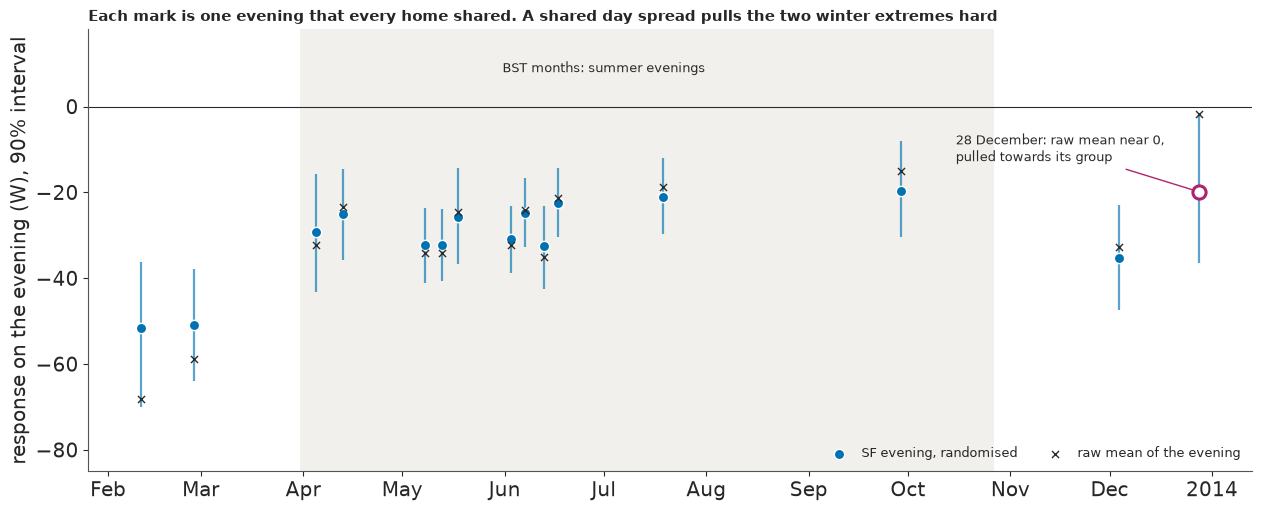

In [20]:
with stage("M4, tau_e prior"):
    sensitivity = {scale: fit_m4(tau_scale=scale) for scale in (10.0, 100.0)}
sensitivity[30.0] = main
print(
    pd.DataFrame(
        {
            f"HalfNormal({scale:.0f})": {
                "tau_e median": np.median(f["tau"]),
                "tau_e 5%": np.quantile(f["tau"], 0.05),
                "tau_e 95%": np.quantile(f["tau"], 0.95),
                "SF winter median": np.median(f["mu"][:, 0]),
                "SF winter sd": f["mu"][:, 0].std(),
            }
            for scale, f in sorted(sensitivity.items())
        }
    )
    .round(1)
    .to_string()
)

check_rng = np.random.default_rng(RANDOM_SEED + 2)
frame_main = main["frame"]
new_day = (
    main["mu"][:, frame_main["group"].to_numpy()]
    + check_rng.normal(0, 1, (4000, len(frame_main))) * main["tau"][:, None]
)
new_mean = new_day + check_rng.normal(0, 1, new_day.shape) * frame_main["se"].to_numpy()
low, high = np.quantile(new_mean, [0.05, 0.95], axis=0)
inside = (frame_main["mean"].to_numpy() >= low) & (frame_main["mean"].to_numpy() <= high)
print(
    f"Check with each day's effect redrawn: {inside.sum()} of {len(frame_main)} event means inside their 90% band. Outside: "
    f"{', '.join(frame_main['day'][~inside])}"
)

with stage("M4, own winter spread"):
    own, own_x = fit_m4(own_spread=True), fit_m4(drop=(DUD_DAY,), own_spread=True)
    own_wide = fit_m4(own_spread=True, tau_scale=60.0)
print(
    pd.DataFrame(
        {
            name: {
                "SF winter median": np.median(f["mu"][:, 0]),
                "5%": np.quantile(f["mu"][:, 0], 0.05),
                "95%": np.quantile(f["mu"][:, 0], 0.95),
                "winter tau_e median": np.median(f["tau"]),
                "tau_e 5%": np.quantile(f["tau"], 0.05),
                "tau_e 95%": np.quantile(f["tau"], 0.95),
                "max r_hat": max_rhat(f),
                "divergences": f["divergences"],
            }
            for name, f in (
                ("own spread, 4 events", own),
                ("own spread, without 28 Dec", own_x),
                ("own spread, 4 events, HalfNormal(60)", own_wide),
            )
        }
    )
    .T.round(2)
    .to_string()
)

fig, ax = plt.subplots(figsize=(12.5, 5), layout="constrained")
bst = pd.date_range("2013-03-31", "2013-10-27")
ax.axvspan(bst[0], bst[-1], color="#f1f0ec", lw=0, zorder=0)
ax.axhline(0, color=INK, lw=0.8)
post_event = main["mu"][:, frame_main["group"].to_numpy()] + main["trace"].posterior["v"].values.reshape(4000, -1)
medians, lo, hi = np.median(post_event, axis=0), *np.quantile(post_event, [0.05, 0.95], axis=0)
winter_raw = frame_main.query("group == 0")["mean"]
print(
    f"28 December: raw {frame_main.loc[frame_main['day'] == DUD_DAY, 'mean'].iloc[0]:.1f} W, shared-spread estimate "
    f"{medians[(frame_main['day'] == DUD_DAY).to_numpy()][0]:.1f} W. Winter mean: sd {main['mu'][:, 0].std():.1f} W in the model, "
    f"raw se of the four {winter_raw.std() / 2:.1f} W"
)
dates = pd.to_datetime(frame_main["day"])
ax.vlines(dates, lo, hi, color=SF_C, lw=1.6, alpha=0.65)
ax.scatter(dates, medians, s=55, color=SF_C, edgecolor="w", lw=1, zorder=3, label="SF evening, randomised")
ax.scatter(dates, frame_main["mean"], s=26, marker="x", color=INK, lw=1, zorder=4, label="raw mean of the evening")
dud = (frame_main["day"] == DUD_DAY).to_numpy()
ax.annotate(
    "28 December: raw mean near 0,\npulled towards its group",
    (dates[dud].iloc[0], medians[dud][0]),
    xytext=(-175, 22),
    textcoords="offset points",
    fontsize=9.5,
    color=INK,
    arrowprops=dict(arrowstyle="-", color=DUD_C, lw=1),
)
ax.scatter(dates[dud], medians[dud], s=90, facecolor="w", edgecolor=DUD_C, lw=2.2, zorder=3)
ax.annotate("BST months: summer evenings", (pd.Timestamp("2013-07-01"), 8), fontsize=9.5, color=INK, ha="center")
ax.set(ylabel="response on the evening (W), 90% interval", ylim=(-85, 18))
ax.xaxis.set_major_formatter(mdates.ConciseDateFormatter(ax.xaxis.get_major_locator()))
ax.legend(loc="lower right", fontsize=9, ncols=2)
ax.set_title(
    "Each mark is one evening that every home shared. A shared day spread pulls the two winter extremes hard",
    loc="left",
    fontsize=11,
);

Start with the raw crosses, and the tables above the figure. Summer evenings sit close together,
about -27 W with a spread of 7 W between events. The four winter evenings read -68, -59, -33 and -2
W, a spread of 30 W. The first table is the plain summary: about -37 to -40 W for the four, about -55 W
for three.

M4 gave no divergences in any of its 19 SF fits, and section 7 prints that count. It does not fully pass
on mixing: the shared fits stay at r_hat 1.01 or below, and four own-spread fits sit above it on `mu` and `tau_e`.
SF winter comes out near -39 W (90% -52 to -26) on the 2013 baseline and about -42 W on the whole
window, or about -51 to -52 W without 28 December. Between events, `tau_e` is about 11 W (5 to 19). It
leans on its prior more than it would with the CM evenings in: HalfNormal(10) gives about 10 W and
narrows the winter sd from about 8 W to about 7 W, while HalfNormal(100) changes almost nothing. On the
whole-window baseline `tau_e` is only about 7 W (1 to 15), so how much days differ depends on the
baseline too.

**Then the check spoils it.** Redraw each day's effect and ask whether the event means could have
come from this model. 14 of 15 fall inside their 90% band, which looks fine, and the one that does not
is 28 December, one of the four evenings the planner cares about. One `tau_e` is set mostly by the 11
summer evenings. It treats 28 December as noise and pulls it from about -2 W to about -20 W, and it
gives the winter mean an sd of 7.9 W, when the four evenings on their own would give a raw standard
error of 15 W.

So we also fit the winter evenings with a day spread of their own. Their mean barely moves, near -40
W, but its 90% interval opens to about -64 to -14 W, with a winter `tau_e` near 28 W (14 to 51). Do
not read that as the right spread. With a HalfNormal(60) prior `tau_e` is near 34 W and the interval
reaches about -72 to -6 W. That fit ends at r_hat 1.02, and three other own-spread fits reach 1.011-1.013,
past the 1.01 we ask for. They stay as they ran, and the figures that rest on them are rounded with
that in mind. These fits use `target_accept=0.99`. At 0.95, on a first run with an empty compile cache, the HalfNormal(60) fit at
this seed gave 75 divergences and an upper limit of +42 W, and on later runs it gave none. **Four
evenings cannot bound their own spread.** That is a finding about the evidence and not a tuning
problem, so both versions go forward. The shared spread is the narrow reading. The own spread is the
wide one, which sits lower above about 100,000 offers and higher below.

## 7. How many homes? The fifth failure

The planner wants a chance, so we build one. On a new winter evening with $N$ homes offered and a
fraction $a$ accepting, the total cut is

$$\text{cut} = N a\,\big(-\mu - v\big) + \sqrt{N a}\;s\,\varepsilon, \qquad v \sim N(0, \tau_e^2),$$

with $s$ the between-home sd of an evening's response. Enrolment shrinks the second term relative to
the first. It does nothing to $\mu$ or $v$. No number of homes averages out a shared bad evening. The
formula treats a new evening as one more draw from the spread of the old ones, which is the
exchangeability assumption from section 6. "1 MW" here is a mean over an event's priced hours.

The planner's 1 MW and the 24% are illustrations. The target and acceptance belong to the planner.
We compare four ways of counting, then drop the model altogether, because the choice between them is
the failure here. The first counts homes, the way a report quoting a fleet-wide standard error does.
The second adds what the four evenings leave unknown about $\mu$. The third adds a new evening's own
$v$. The fourth gives winter its own day spread. The last line has no model at all: the next evening is
one of the four, equally likely.

In [21]:
Z_DAY, Z_HOMES = np.random.default_rng(RANDOM_SEED + 3).normal(0, 1, (2, 4000))


def chance(fit, group, offers, acceptance=ACCEPTANCE, target_mw=1.0, shared=True):
    """P(total cut >= target) on one new evening, for scalar or array offers."""
    homes = np.asarray(offers, float)[..., None] * acceptance
    day = fit["tau"] * Z_DAY if shared else 0.0
    cut = -homes * (fit["mu"][:, group] + day) - np.sqrt(homes) * fit["sd"] * Z_HOMES
    return (cut >= target_mw * 1e6).mean(axis=-1)


def counting_homes(baseline="local", drop=(), offers=1e5, acceptance=ACCEPTANCE, target_mw=1.0):
    """The fleet treated as the sample: every home an independent draw, the four evenings forgotten."""
    frame = event_means(baseline, drop)
    picked = frame[frame["group"] == 0]
    keep = cells["day"].isin(picked["day"]) & (cells["effect"] == "SF High evening")
    per_home = np.nanmean(home_tables[baseline][:, cells[keep].index], axis=1)
    mean, sd = np.nanmean(per_home), np.nanstd(per_home, ddof=1)
    se = sd / np.sqrt(np.isfinite(per_home).sum())
    homes = np.asarray(offers, float) * acceptance
    return stats.norm.cdf((-homes * mean - target_mw * 1e6) / np.sqrt(homes**2 * se**2 + homes * sd**2))


def face_value(baseline="local", drop=(), offers=1e5, acceptance=ACCEPTANCE, target_mw=1.0):
    """No model of the day: the next evening is one of the observed evenings, equally likely."""
    frame = event_means(baseline, drop)
    means = frame[frame["group"] == 0]["mean"].to_numpy()
    homes = np.asarray(offers, float)[..., None] * acceptance
    return (-homes * means >= target_mw * 1e6).mean(axis=-1)


OFFERS = (50_000, 100_000, 200_000)
with stage("M4, one row borrowing CM"):
    borrowed = fit_m4(frame=event_means(kinds=("SF", "CM")))  # never feeds a headline: gate P5 failed
rows = {}
for (baseline, label), fit in fits.items():
    name = f"SF winter, {'2013 month x band' if baseline == 'local' else 'whole window'}, {label}"
    rows[name] = {f"{o:,}": float(chance(fit, 0, o)) for o in OFFERS}
rows["SF winter, own day spread, all 4"] = {f"{o:,}": float(chance(own, 0, o)) for o in OFFERS}
rows["SF winter, own day spread, without 28 Dec"] = {f"{o:,}": float(chance(own_x, 0, o)) for o in OFFERS}
rows["SF winter, day spread borrowed from 17 CM evenings: NOT randomised, outside every headline range"] = {
    f"{o:,}": float(chance(borrowed, 0, o)) for o in OFFERS
}
rows["CM winter, 2013 month x band: NOT randomised, outside every headline range"] = {
    f"{o:,}": float(chance(borrowed, 2, o)) for o in OFFERS
}
delivery_table = pd.DataFrame(rows).T
cm_placebo = f"{placebo['CM High evening']['mean_w']:+.1f} W, gate failed"
print(f"P(at least 1 MW off one winter evening), {ACCEPTANCE:.0%} acceptance (an assumption), by homes offered")
print(
    delivery_table.round(2)
    .assign(**{"CM placebo": [""] * (len(delivery_table) - 2) + [cm_placebo] * 2})
    .to_string()
)
ways = {
    "counting homes": [float(counting_homes(offers=o)) for o in OFFERS],
    "adding uncertainty in mu": [float(chance(main, 0, o, shared=False)) for o in OFFERS],
    "adding a new evening's v": [float(chance(main, 0, o)) for o in OFFERS],
    "winter with its own day spread": [float(chance(own, 0, o)) for o in OFFERS],
    "the 4 evenings at face value": [float(face_value(offers=o)) for o in OFFERS],
}
print("\nFour ways of counting, then no model at all, 2013 month x band, all 4 events:")
print(pd.DataFrame(ways, index=[f"{o:,}" for o in OFFERS]).T.round(2).to_string())
dud_read = {b: float(event_means(b).set_index("day").loc[DUD_DAY, "mean"]) for b in ("local", "plan")}
print(
    "\n28 December reaches 1 MW at "
    + ", ".join(
        f"{-1e6 / w:,.0f} accepting homes, {-1e6 / w / ACCEPTANCE:,.0f} offers ({w:.1f} W, {name})"
        for w, name in ((dud_read["local"], "2013 month x band"), (dud_read["plan"], "whole window"))
    )
)

P(at least 1 MW off one winter evening), 24% acceptance (an assumption), by homes offered
                                                                                                  50,000  100,000  200,000            CM placebo
SF winter, 2013 month x band, all 4 winter events                                                   0.01     0.42     0.91                      
SF winter, 2013 month x band, without 28 Dec                                                        0.00     0.85     1.00                      
SF winter, whole window, all 4 winter events                                                        0.00     0.49     0.97                      
SF winter, whole window, without 28 Dec                                                             0.00     0.90     1.00                      
SF winter, own day spread, all 4                                                                    0.10     0.46     0.72                      
SF winter, own day spread, without 28 De

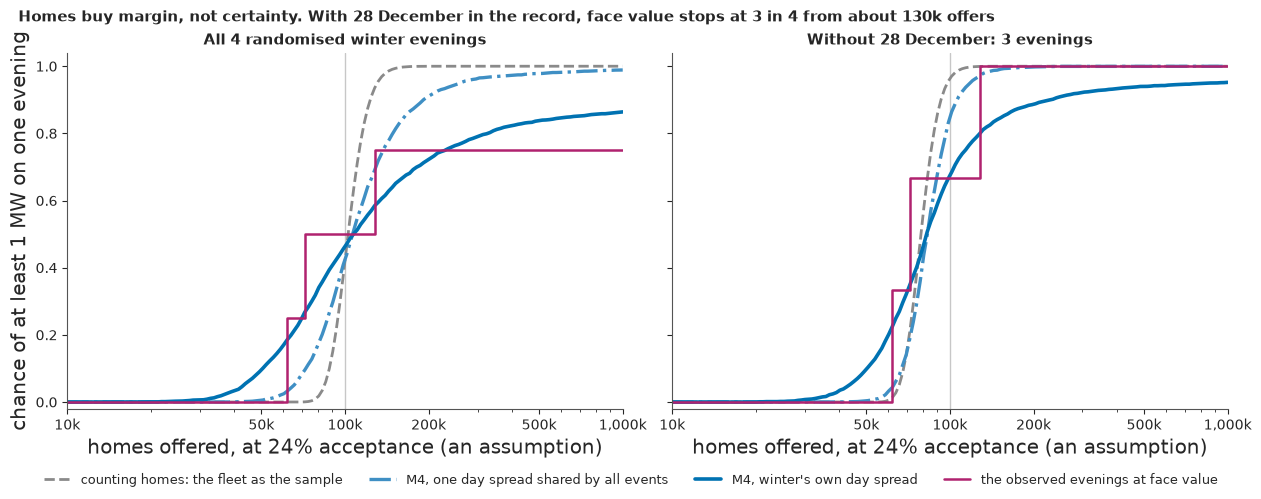

In [22]:
grid = np.geomspace(1e4, 1e6, 160)
fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.9), sharey=True, layout="constrained")
for ax, fit, wide, drop, title in zip(
    axes,
    (main, main_x),
    (own, own_x),
    ((), (DUD_DAY,)),
    ("All 4 randomised winter evenings", "Without 28 December: 3 evenings"),
):
    ax.axvline(1e5, color="#c7c7c7", lw=1)
    ax.plot(
        grid,
        counting_homes(drop=drop, offers=grid),
        color=MUTED,
        lw=2,
        ls="--",
        label="counting homes: the fleet as the sample",
    )
    ax.plot(grid, chance(fit, 0, grid), color=SKY, lw=2.4, ls="-.", label="M4, one day spread shared by all events")
    ax.plot(grid, chance(wide, 0, grid), color=SF_C, lw=2.6, label="M4, winter's own day spread")
    ax.step(
        grid,
        face_value(drop=drop, offers=grid),
        where="post",
        color=DUD_C,
        lw=1.8,
        label="the observed evenings at face value",
    )
    ax.set_title(title, fontsize=10.5)
    ax.tick_params(labelsize=10)
    ax.set(
        xscale="log",
        xlabel=f"homes offered, at {ACCEPTANCE:.0%} acceptance (an assumption)",
        ylim=(-0.02, 1.04),
        xlim=(1e4, 1e6),
    )
    ax.xaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{v / 1000:,.0f}k"))
    ax.set_xticks([1e4, 5e4, 1e5, 2e5, 5e5, 1e6])
axes[0].set_ylabel("chance of at least 1 MW on one evening")
fig.legend(*axes[0].get_legend_handles_labels(), loc="outside lower center", ncols=4, fontsize=9.5)
fig.suptitle(
    "Homes buy margin, not certainty. With 28 December in the record, face value stops at 3 in 4 from about 130k offers",
    x=0.01,
    ha="left",
    fontsize=11,
);

Accepting homes needed on one winter evening (divide by the acceptance rate for offers; NaN: not reached by 4 million):
                               P = 0.5   P = 0.8  P = 0.95
0.5 MW, shared spread, all 4   12900.0   18000.0   31200.0
1.0 MW, shared spread, all 4   26000.0   35600.0   62700.0
2.0 MW, shared spread, all 4   51400.0   71600.0  126100.0
0.5 MW, own spread, all 4      12900.0   38700.0       NaN
1.0 MW, own spread, all 4      26000.0   79200.0       NaN
2.0 MW, own spread, all 4      51400.0  156500.0       NaN
0.5 MW, own spread, no 28 Dec   9900.0   15500.0  108600.0
1.0 MW, own spread, no 28 Dec  19900.0   31200.0  207600.0
2.0 MW, own spread, no 28 Dec  40000.0   61700.0  424200.0


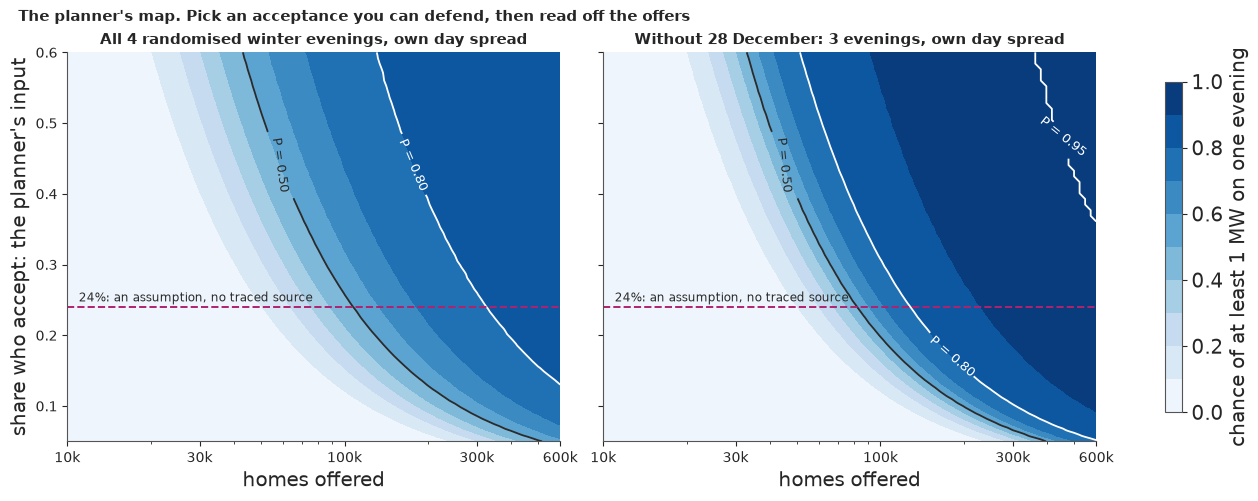

In [23]:
offers_axis = np.geomspace(1e4, 6e5, 90)
acceptance_axis = np.linspace(0.05, 0.6, 70)
fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.9), sharey=True, layout="constrained")
for ax, fit, title in zip(
    axes,
    (own, own_x),
    ("All 4 randomised winter evenings, own day spread", "Without 28 December: 3 evenings, own day spread"),
):
    surface = np.array([[float(chance(fit, 0, o, acceptance=a)) for o in offers_axis] for a in acceptance_axis])
    filled = ax.contourf(offers_axis, acceptance_axis, surface, levels=np.linspace(0, 1, 11), cmap="Blues")
    lines = ax.contour(
        offers_axis, acceptance_axis, surface, levels=[0.5, 0.8, 0.95], colors=[INK, "white", "white"], linewidths=1.3
    )
    ax.clabel(lines, fmt=lambda v: f"P = {v:.2f}", fontsize=9)
    ax.axhline(ACCEPTANCE, color=DUD_C, lw=1.4, ls="--")
    ax.annotate(
        "24%: an assumption, no traced source",
        (1.1e4, ACCEPTANCE),
        xytext=(0, 4),
        textcoords="offset points",
        fontsize=8.8,
        color=INK,
    )
    ax.set_title(title, fontsize=10.5)
    ax.tick_params(labelsize=10)
    ax.set(xscale="log", xlabel="homes offered")
    ax.xaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{v / 1000:,.0f}k"))
    ax.set_xticks([1e4, 3e4, 1e5, 3e5, 6e5])
axes[0].set_ylabel("share who accept: the planner's input")
fig.colorbar(filled, ax=axes, shrink=0.85, label="chance of at least 1 MW on one evening")
fig.suptitle(
    "The planner's map. Pick an acceptance you can defend, then read off the offers", x=0.01, ha="left", fontsize=11
)


def homes_needed(fit, target_mw, probability):
    """Accepting homes needed for this chance, on a fine grid."""
    homes = np.geomspace(1e3, 4e6, 500)
    p = chance(fit, 0, homes, acceptance=1.0, target_mw=target_mw)
    reached = np.flatnonzero(p >= probability)
    return float(homes[reached[0]]) if reached.size else float("nan")


need = pd.DataFrame(
    {
        f"{target} MW, {label}": {f"P = {p}": homes_needed(fit, target, p) for p in (0.5, 0.8, 0.95)}
        for label, fit in (
            ("shared spread, all 4", main),
            ("own spread, all 4", own),
            ("own spread, no 28 Dec", own_x),
        )
        for target in (0.5, 1.0, 2.0)
    }
).T
print(
    "Accepting homes needed on one winter evening (divide by the acceptance rate for offers; NaN: not reached by 4 million):"
)
print(need.round(-2).to_string());

Start with 100,000 offers. At 24% that is 24,000 homes, and 1 MW then needs about 42 W each, almost
exactly the estimate. So every version sits near an even chance with all four evenings (0.38-0.50) and
moves to 0.7-0.9 without 28 December. Nobody should read one figure from that row without the other.
At 50,000 offers no version passes about 0.1, on the 2013 baseline or the whole window.

**The fifth failure is at 200,000.** Count homes, as a fleet-wide standard error does, and the curve
is a cliff that hits 1.00. It says a thousand homes settled the matter. The shared-spread curve is
only a little kinder, at 0.91, or 0.97 on the whole-window baseline. Let winter have its own spread and
it is about 0.72. Take the four evenings at face value and it is 0.75. The dashed curve is the mistake
to avoid, because each extra home shrinks only the noise that was already small. **The fix** is to
count what limits you.

Is 3 in 4 a ceiling? Only at face value, and only at any scale a planner would consider. 28 December
read -1.7 W, not zero (se 10), and at that figure it reaches 1 MW at about 582,000 accepting homes,
about 2.4 million offers. On the whole-window baseline it read -8.7 W, which gives about 480,000
offers. So one in four falls short at any realistic enrolment if you take the evenings as they read.
The own-spread model lets winter vary and gives about 0.72 at 200,000 offers and about 0.8 near
330,000. Four evenings cannot settle which is right.

Arithmetic from published inputs says 1 MW needs about 20,000 responding homes at the CM peak figure of
50 W, or about 83,000 offers at 24%. At the SF figure of about 30 W it is about 33,000 homes and about
139,000 offers. In the table, a 50% chance needs about 26,000 accepting homes (about 108,000 offers).
An 80% chance needs about 36,000 (about 148,000 offers) under a shared spread and about 79,000 (about
330,000 offers) under winter's own. That curve is nearly flat there, so small changes to the fit move
this figure a lot: 75,000 to 83,000 have all appeared. P = 0.95 is not reached by 4 million homes in
that version. Without 28 December the same 80% needs about 31,000 homes. The map above is the same
answer as a picture for any acceptance, drawn with the wide spread, so the planner can substitute a
defensible rate.

The last two rows of the delivery table are not part of that answer, and neither is in any range in
this notebook. Their days were placed, and the placebo beside them failed its gate. CM winter's 0.81 at
100,000 offers looks better than anything above, and it rests on days nobody randomised.

### How much rests on each evening, and on what counts as the peak

Four more checks, all after the fact. Dropping 28 December is only one of four ways to lose an evening,
so the first table loses each in turn. The second line shows what borrowing the 17 CM evenings would
change. It is not randomised, it sits beside the failed placebo, and it enters no range. The third
treats the frequency of a dead evening as an input instead of reading 1 in 4 off the record. The last
asks what happens at the hours a planner calls the peak.

In [24]:
leave_out, left_fits = {}, {}
with stage("M4, each evening left out"):
    for day in winter_days:
        pair = (main_x, own_x) if day == DUD_DAY else (fit_m4(drop=(day,)), fit_m4(drop=(day,), own_spread=True))
        if day != DUD_DAY:
            left_fits[f"shared, without {day}"], left_fits[f"own, without {day}"] = pair
        leave_out[f"without {pd.Timestamp(day):%-d %b}"] = {
            "shared, 100,000": float(chance(pair[0], 0, 100_000)),
            "own, 100,000": float(chance(pair[1], 0, 100_000)),
            "shared, 200,000": float(chance(pair[0], 0, 200_000)),
            "own, 200,000": float(chance(pair[1], 0, 200_000)),
            "SF winter median (shared)": np.median(pair[0]["mu"][:, 0]),
        }
print("Leave one winter evening out, P(1 MW):")
print(pd.DataFrame(leave_out).T.round(2).to_string())
print(
    f"\nDay spread with 17 CM evenings borrowed, NOT randomised, CM placebo {cm_placebo}: tau_e {np.median(borrowed['tau']):.1f} W "
    f"against {np.median(main['tau']):.1f} W on the 15 SF evenings; P(1 MW) {float(chance(borrowed, 0, 100_000)):.2f} at 100,000 offers, "
    f"{float(chance(borrowed, 0, 200_000)):.2f} at 200,000, against {float(chance(main, 0, 100_000)):.2f} and {float(chance(main, 0, 200_000)):.2f}"
)

gmt_days = ((days_2013 < "2013-03-31") | (days_2013 >= "2013-10-27")).sum()
fortnight = ((days_2013 >= "2013-12-20") | (days_2013 <= "2013-01-02")).sum()
print(f"\nA share w of winter evenings deliver nothing, the rest follow the 3-evening fits (own to shared spread):")
print(
    pd.DataFrame(
        {
            f"w = {w:.0%}{', post-hoc' if w < 0.25 else ''}": {
                "ceiling": f"{1 - w:.2f}",
                **{
                    f"{o:,} offers": f"{(1 - w) * float(chance(own_x, 0, o)):.2f}-{(1 - w) * float(chance(main_x, 0, o)):.2f}"
                    for o in (100_000, 200_000)
                },
            }
            for w in (fortnight / gmt_days, 0.25)
        }
    ).T.to_string()
)
print(
    f"w = {fortnight / gmt_days:.0%} is {fortnight} of {gmt_days} GMT days, 20 December to 2 January, a window drawn after seeing the data; "
    "25% is 1 in 4 evenings"
)

flat_winter = (wall.month <= 2) & (wall.dayofweek < 5) & in_2013
flat_hours = pd.Series(1000 * panel_kw[flat_winter]).groupby(hour_of_day[flat_winter]).mean()
print("\nFlat-home load, Jan-Feb 2013 weekdays, W by wall hour:", flat_hours.loc[16:21].round(0).astype(int).to_dict())
evening_load = pd.Series(1000 * panel_kw[evening & in_2013]).groupby(trial_day[evening & in_2013]).mean()
winter_load = evening_load[(evening_load.index < "2013-03-31") | (evening_load.index >= "2013-10-27")]
print(
    f"Highest-load evenings of 2013: {sum(d[5:7] == '01' for d in evening_load.nlargest(10).index)} of 10 in January, and no randomised "
    f"evening High event falls in January. 28 December sits at percentile {(winter_load < winter_load[DUD_DAY]).mean():.0%} of winter evenings, "
    f"and the highest evening from 20-31 December at {(winter_load < winter_load[winter_load.index >= '2013-12-20'].max()).mean():.0%}"
)


def peak_frame():
    """event_means with each mean replaced by the fleet response at 18:00-20:00, for events priced in both hours."""
    frame = event_means()
    peak = (hour_of_day >= 18) & (hour_of_day < 20)
    values = []
    for _, row in frame.iterrows():
        hours = peak & (trial_day == row["day"])
        priced = (effect[hours] == EFFECTS.index(f"{row['kind']} High evening")).sum()
        values.append(np.nanmean(fleet_response[hours]) if priced == 2 else np.nan)
    return frame.assign(mean=values).dropna(subset=["mean"])


peak_events = peak_frame()
with stage("M4, peak hours"):
    peak_fits = {
        "shared, all": fit_m4(frame=peak_events),
        "own, all": fit_m4(frame=peak_events, own_spread=True),
        "shared, without 28 Dec": fit_m4(frame=peak_events[peak_events["day"] != DUD_DAY]),
        "own, without 28 Dec": fit_m4(frame=peak_events[peak_events["day"] != DUD_DAY], own_spread=True),
    }
four_evenings = pd.DataFrame(
    {
        pd.Timestamp(day).strftime("%-d %b"): {
            "event hours (W)": local_means[day],
            "fleet, 18:00-20:00 (W)": np.nanmean(fleet_response[(trial_day == day) & (hour_of_day >= 18) & (hour_of_day < 20)]),
            "priced at 18:00-20:00": day in set(peak_events["day"]),
        }
        for day in winter_days
    }
).T
print(four_evenings.to_string())
same_fits = dict(zip(peak_fits, (main, own, main_x, own_x)))
every_fit = {
    **{f"shared, {k[0]}, {k[1]}": f for k, f in fits.items()},
    "shared, HalfNormal(10)": sensitivity[10.0],
    "shared, HalfNormal(100)": sensitivity[100.0],
    "own, all": own,
    "own, without 28 Dec": own_x,
    "own, HalfNormal(60)": own_wide,
    **left_fits,
    **{f"peak hours, {k}": f for k, f in peak_fits.items()},
}
hats = {name: max_rhat(f) for name, f in every_fit.items()}
own_fits = [f for name, f in every_fit.items() if "own" in name]
print(
    f"The {len(every_fit)} M4 fits on SF evenings: {sum(f['divergences'] for f in every_fit.values())} divergences, "
    f"{sum(f['divergences'] for f in own_fits)} of them in the {len(own_fits)} own-spread fits at target_accept=0.99. "
    f"Fits over r_hat 1.01: { {k: round(v, 3) for k, v in hats.items() if v > 1.01} or 'none'}. "
    f"The one CM-borrowing row: {borrowed['divergences']} divergences, r_hat {max_rhat(borrowed):.2f}"
)
print(
    pd.DataFrame(
        {
            name: {
                "priced hours, 100,000": float(chance(same_fits[name], 0, 100_000)),
                "18:00-20:00, 100,000": float(chance(fit, 0, 100_000)),
                "priced hours, 200,000": float(chance(same_fits[name], 0, 200_000)),
                "18:00-20:00, 200,000": float(chance(fit, 0, 200_000)),
            }
            for name, fit in peak_fits.items()
        }
    )
    .T.round(2)
    .to_string()
)
winter_peaks = peak_events.query("group == 0")["mean"].to_numpy()
print(
    f"At face value, 100,000 offers: {(-24_000 * winter_peaks >= 1e6).sum()} of {len(winter_peaks)} evenings at 18:00-20:00, "
    f"{(-24_000 * frame_main.query('group == 0')['mean'] >= 1e6).sum()} of 4 over priced hours"
)

Leave one winter evening out, P(1 MW):
                shared, 100,000  own, 100,000  shared, 200,000  own, 200,000  SF winter median (shared)
without 11 Feb             0.22          0.35             0.83          0.62                     -32.19
without 27 Feb             0.20          0.38             0.83          0.63                     -31.87
without 4 Dec              0.51          0.49             0.92          0.72                     -42.15
without 28 Dec             0.85          0.67             1.00          0.89                     -50.51

Day spread with 17 CM evenings borrowed, NOT randomised, CM placebo +13.2 W, gate failed: tau_e 8.4 W against 11.1 W on the 15 SF evenings; P(1 MW) 0.40 at 100,000 offers, 0.95 at 200,000, against 0.42 and 0.91

A share w of winter evenings deliver nothing, the rest follow the 3-evening fits (own to shared spread):
                 ceiling 100,000 offers 200,000 offers
w = 9%, post-hoc    0.91      0.61-0.77      0.81-0.91
w = 25%      

       event hours (W) fleet, 18:00-20:00 (W) priced at 18:00-20:00
11 Feb      -68.126151             -82.010744                  True
27 Feb      -58.793008             -74.880279                  True
4 Dec       -32.623915               7.165794                 False
28 Dec       -1.719383              12.846456                  True


The 19 M4 fits on SF evenings: 0 divergences, 0 of them in the 8 own-spread fits at target_accept=0.99. Fits over r_hat 1.01: {'own, all': 1.013, 'own, HalfNormal(60)': 1.021, 'own, without 2013-12-04': 1.011, 'peak hours, own, all': 1.011}. The one CM-borrowing row: 0 divergences, r_hat 1.00
                        priced hours, 100,000  18:00-20:00, 100,000  priced hours, 200,000  18:00-20:00, 200,000
shared, all                              0.42                  0.57                   0.91                  0.83
own, all                                 0.46                  0.53                   0.72                  0.70
shared, without 28 Dec                   0.85                  1.00                   1.00                  1.00
own, without 28 Dec                      0.67                  0.94                   0.89                  0.98
At face value, 100,000 offers: 2 of 3 evenings at 18:00-20:00, 2 of 4 over priced hours


**One evening swings it both ways.** Lose 28 December and 100,000 offers reads 0.85 or 0.67. Lose either
February evening and it reads about 0.2 on the shared spread and about 0.35-0.38 on winter's own. So the
28 December rows are not the only sensitivity, just the one with a story attached.

**Borrowing from CM.** The headline fits use the 15 SF evenings and nothing else. Borrow the 17 CM
evenings and the shared spread falls from about 11 W to about 8 W, and 200,000 offers rises from 0.91
to 0.95. That row is not randomised, the +13.2 W placebo beside it failed its gate, and it is outside
every headline range. It is here to show the size of what P5 took away, and that is small. The
stored CM cells also left the baselines behind the SF figures, which moved no evening by more than
0.7 W.

**How often is a dead evening?** The 25% row is the raw count of 1 in 4, whose 95% interval runs from
under 1% to about 81%. The 9% row is a post-hoc sensitivity: late December is a part of the calendar
known in advance, but this fortnight was drawn after seeing the data. If the dead run is confined to
it, about 9% of winter days, the ceiling is about 0.91 and 200,000 offers reads about 0.8-0.9. That
assumes the confinement, which one December cannot show. The planner should also ask whether late
December is a peak that needs covering at all: 28 December sits low among winter evenings, and no
evening from 20 to 31 December reaches the top quartile of winter load.

**The peak is not the mean.** Flat-home load in January and February peaks at 18:00-20:00. 4 December
was priced only from 20:00, so it says nothing about those hours, and **3 evenings priced the peak**,
not 4. Those three read about -82, -75 and +13 W on the fleet mean, so 100,000 offers reads about
0.5-0.6 with all three (2 of 3 at face value) and about 0.9-1.0 without 28 December. The 17:00 hour is a
slow ramp and dilutes the longer means, which is why these sit above the priced-hours figures at
100,000 offers. At 200,000 offers the own-spread answer barely changes and the shared figure drops
below its priced-hours one. These fits borrow each event's standard error
from its priced-hours cell, because the stored table has no peak-hour cells, so the shared-spread
figure in particular is rough. And January, which holds 8 of the 10 highest-load evenings of 2013, has
no randomised evening event at all.

## 8. The best responders, and the sixth failure

The published claim is that the best 25% of homes give three times the mean. If that holds, the
planner should chase them. The plan reads it as ranked on the same events it then reports, which we
could not confirm. A home's estimate on an event is noisy, so the top of any such ranking is partly the
luckiest noise.

Here is the trap as a picture. Each panel is homes x SF High evening events, in rows of about 20 homes,
blue where load fell. Left, sorted on its own events, a tidy gradient, and it looks like a discovery.
Middle, sorted on some events and shown on others. Right, the same tidy recipe on the **placebo**, 2012
evenings with no price at all.

28 December, top quartile ranked on the other 14 evenings against the rest: -8.6 W (se 26)


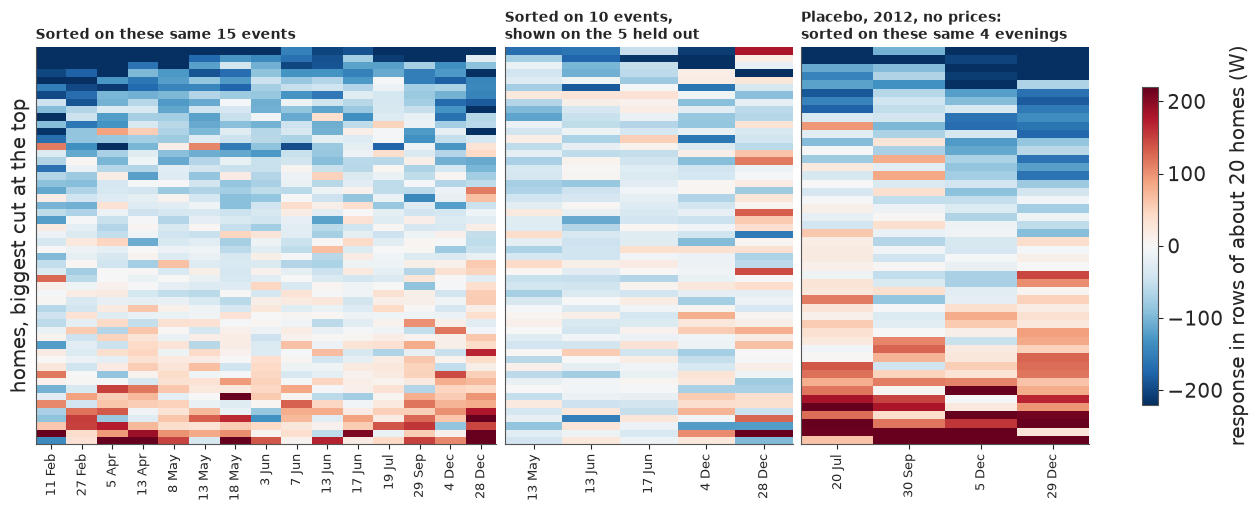

In [25]:
def repeats():
    """SF High evening cells with their repeat number within each event type (start hour, length)."""
    frame = cells[cells["effect"] == "SF High evening"].copy()
    frame["repeat"] = frame.groupby(["start_hour", "event_hours"]).cumcount()
    return frame


def weighted(table, columns, weights):
    seen = np.isfinite(table[:, columns])
    return np.nansum(table[:, columns] * weights[columns], axis=1) / np.where(
        seen @ weights[columns] > 0, seen @ weights[columns], np.nan
    )


def blocks(matrix, size=20):
    """Block means over rows of homes: a large raster stays readable and small."""
    n = len(matrix) // size
    return np.nanmean(matrix[: n * size].reshape(n, size, -1), axis=1)


frame_r = repeats()
r_local = home_tables["local"][:, frame_r.index]
hours_w = frame_r["hours"].to_numpy(float)
rep = frame_r["repeat"].to_numpy()
own_rank = np.argsort(np.nan_to_num(weighted(r_local, np.arange(15), hours_w), nan=0.0))
train_score = weighted(r_local, np.flatnonzero(rep != 2), hours_w)
held_rank = np.argsort(np.nan_to_num(train_score, nan=0.0))
held_columns = np.flatnonzero(rep == 2)
p_sel = placebo_cells[placebo_cells["effect"] == "SF High evening"]
r_placebo = placebo_table[:, p_sel.index]
placebo_rank = np.argsort(np.nan_to_num(np.nanmean(r_placebo, axis=1), nan=0.0))

fig, axes = plt.subplots(1, 3, figsize=(12.5, 5), layout="constrained", width_ratios=(1.6, 1, 1))
norm = TwoSlopeNorm(vcenter=0, vmin=-220, vmax=220)
for ax, matrix, title, days in zip(
    axes,
    (r_local[own_rank], r_local[held_rank][:, held_columns], r_placebo[placebo_rank]),
    (
        "Sorted on these same 15 events",
        "Sorted on 10 events,\nshown on the 5 held out",
        "Placebo, 2012, no prices:\nsorted on these same 4 evenings",
    ),
    (
        frame_r["day"].to_numpy(),
        frame_r["day"].to_numpy()[held_columns],
        pd.to_datetime(p_sel["day"]) - pd.Timedelta(days=364),  # the real evenings of 2012
    ),
):
    art = ax.imshow(blocks(matrix), aspect="auto", interpolation="nearest", cmap="RdBu_r", norm=norm)
    ax.set_title(title, loc="left", fontsize=10)
    ax.set_xticks(range(len(days)), [pd.Timestamp(d).strftime("%-d %b") for d in days], rotation=90, fontsize=9)
    ax.set_yticks([])
axes[0].set_ylabel("homes, biggest cut at the top")
fig.colorbar(art, ax=axes, shrink=0.8, label="response in rows of about 20 homes (W)")
dud_column_r = int(np.flatnonzero(frame_r["day"].to_numpy() == DUD_DAY)[0])
rank_14 = weighted(r_local, np.delete(np.arange(15), dud_column_r), hours_w)
top_14 = rank_14 <= np.nanquantile(rank_14, 0.25)
dud_w = r_local[:, dud_column_r]
gap_se = np.sqrt(
    np.nanvar(dud_w[top_14], ddof=1) / np.isfinite(dud_w[top_14]).sum()
    + np.nanvar(dud_w[~top_14], ddof=1) / np.isfinite(dud_w[~top_14]).sum()
)
print(
    f"28 December, top quartile ranked on the other 14 evenings against the rest: "
    f"{np.nanmean(dud_w[top_14]) - np.nanmean(dud_w[~top_14]):+.1f} W (se {gap_se:.0f})"
);

Homes outside the 95% funnel: priced 34.0%, placebo 30.0%
Below the funnel only: priced 27.5%, placebo 16.0%
Median textbook se of a home: 27 W priced, 55 W placebo; between-home sd 80 W, 164 W
The same 4 evenings with prices, 2013: between-home sd 160 W, so 4 against 15 evenings explains most of 164 W against 80 W


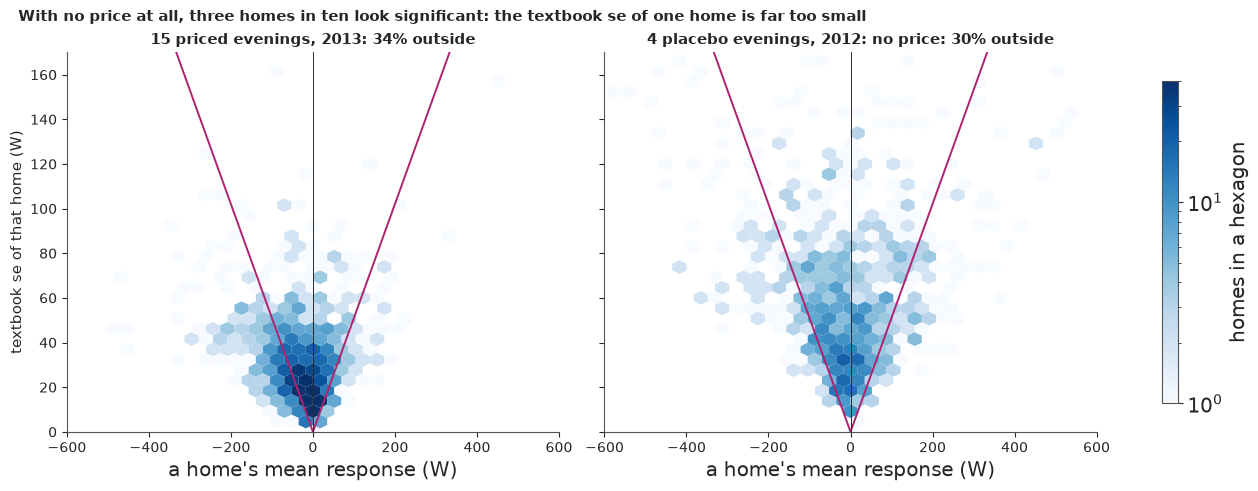

In [26]:
def funnel_points(table, weights, sigma):
    seen = np.isfinite(table)
    effect_home = np.nansum(table * weights, axis=1) / np.where(seen @ weights > 0, seen @ weights, np.nan)
    se = sigma / np.sqrt(seen @ weights)
    ok = np.isfinite(effect_home) & np.isfinite(se)
    return effect_home[ok], se[ok]


real_x, real_se = funnel_points(r_local, hours_w, watts(table_file["sigma_w"]))
fake_x, fake_se = funnel_points(r_placebo, p_sel["hours"].to_numpy(float), watts(table_file["placebo_sigma_w"]))
fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.8), sharey=True, sharex=True, layout="constrained")
for ax, x, se, title in zip(
    axes, (real_x, fake_x), (real_se, fake_se), ("15 priced evenings, 2013", "4 placebo evenings, 2012: no price")
):
    art = ax.hexbin(
        x, se, gridsize=46, extent=(-800, 800, 0, 240), cmap="Blues", norm=LogNorm(1, 40), mincnt=1, linewidths=0
    )
    grid_se = np.linspace(0, 240, 20)
    ax.plot(1.96 * grid_se, grid_se, color=DUD_C, lw=1.4)
    ax.plot(-1.96 * grid_se, grid_se, color=DUD_C, lw=1.4)
    ax.axvline(0, color=INK, lw=0.7)
    share = (np.abs(x) > 1.96 * se).mean()
    ax.set_title(f"{title}: {share:.0%} outside", fontsize=10.5)
    ax.tick_params(labelsize=10)
    ax.set(xlabel="a home's mean response (W)", xlim=(-600, 600), ylim=(0, 170))
axes[0].set_ylabel("textbook se of that home (W)", fontsize=10.5)
fig.colorbar(art, ax=axes, shrink=0.85, label="homes in a hexagon")
fig.suptitle(
    "With no price at all, three homes in ten look significant: the textbook se of one home is far too small",
    x=0.01,
    ha="left",
    fontsize=11,
)
print(
    f"Homes outside the 95% funnel: priced {(np.abs(real_x) > 1.96 * real_se).mean():.1%}, placebo {(np.abs(fake_x) > 1.96 * fake_se).mean():.1%}"
)
print(
    f"Below the funnel only: priced {(real_x < -1.96 * real_se).mean():.1%}, placebo {(fake_x < -1.96 * fake_se).mean():.1%}"
)
print(
    f"Median textbook se of a home: {np.median(real_se):.0f} W priced, {np.median(fake_se):.0f} W placebo; "
    f"between-home sd {real_x.std():.0f} W, {fake_x.std():.0f} W"
)
matching = np.flatnonzero(frame_r["day"].isin(p_sel["day"]).to_numpy())
print(
    f"The same 4 evenings with prices, 2013: between-home sd {np.nanstd(weighted(r_local, matching, hours_w)):.0f} W, "
    f"so 4 against 15 evenings explains most of 164 W against 80 W"
);

Middle against left is the arithmetic of ranking. Sorting on the data you display makes a gradient
appear even where nothing is there, and the placebo on the right shows one with no price in existence.
It looks stronger than the left panel mainly because it averages 4 evenings and not 15. The middle
panel is what the ranking still knows on evenings it did not use: the top rows still lean blue, far
more faintly. 28 December cannot be read here: ranked on the other 14 evenings, the top quartile's gap
is about -9 W with an se of 26, which fits both nothing and a typical gap.

The funnels show why a home's own estimate is not to be trusted. A funnel drawn from the textbook
standard error should hold 95% of homes when nothing is happening. In the placebo it holds 70%. Hourly
load comes in bursts, not independent draws, so one home's se of 27-55 W is far too small, and the
real spread between homes is 80 W on 15 evenings and 164 W on 4. That gap is mostly the number of
evenings, as the last printed line shows. Priced homes do lean the right way:
27.5% fall below the funnel against 16.0% in the placebo. So there is a real response in there, and
a list of "best homes" read off one table is still mostly a list of noise.

**The fix** is the rule for any such claim: rank on some events, score on others. Each SF type has
three repeats, so we do that three times. Then the honest alternative: an operator has no event
history, only past load, so we also rank on evening load from before the trial, which a price
cannot have touched.

                             held out  top, same events  top, held out  all homes, held out  ratio  se of top (homes)
  11 Feb, 27 Feb, 5 Apr, 8 May, 7 Jun            -127.5          -88.5                -41.8    2.1               10.9
13 Apr, 18 May, 3 Jun, 19 Jul, 29 Sep            -147.9          -57.2                -23.0    2.5               11.5
13 May, 13 Jun, 17 Jun, 4 Dec, 28 Dec            -148.4          -48.2                -22.5    2.1                9.5

All homes -29.1 W. Top quartile -141.3 W on the same events, -64.6 W held out: 2.2x the mean, against the published 3x. Held-out fold ratios 2.1 to 2.5.
Lost going from same-event to held-out: 54%
Same-event ranking on this table: 4.9x the mean
Correlation of a home's response between ranked and held-out events, by fold: [0.19, 0.14, 0.11]
Whole-window baseline: held out -96.3 W, all homes -41.7 W
Ranked on Jul-Dec 2012 evening load, all 15 events: top quartile -46.4 W (se 7.3), all -29.2 W, the rest -23.5 W: 1.6x
As a sh

Home bootstrap, 90%: held-out ratio 1.92 to 2.58; share of load, top quartile minus everyone -1.5 to -0.0 points


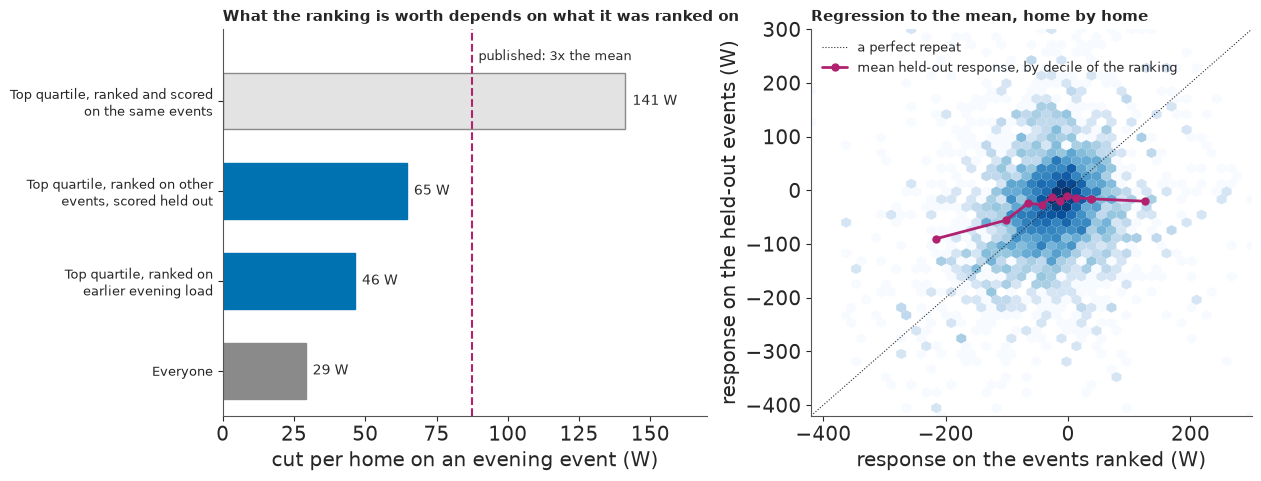

In [27]:
def targeting(baseline="local", top=0.25):
    """Cross-fit on repeats, and rank on pre-trial evening load. Means in W, top against everyone."""
    frame = repeats()
    table = home_tables[baseline][:, frame.index]
    weights, repeat = frame["hours"].to_numpy(float), frame["repeat"].to_numpy()
    folds = []
    for fold in range(3):
        train, test = np.flatnonzero(repeat != fold), np.flatnonzero(repeat == fold)
        score, held = weighted(table, train, weights), weighted(table, test, weights)
        chosen = score <= np.nanquantile(score, top)
        folds.append(
            {
                "held out": ", ".join(pd.Timestamp(d).strftime("%-d %b") for d in frame["day"].to_numpy()[test]),
                "top, same events": np.nanmean(score[chosen]),
                "top, held out": np.nanmean(held[chosen]),
                "all homes, held out": np.nanmean(held),
                "ratio": np.nanmean(held[chosen]) / np.nanmean(held),
                "se of top (homes)": np.nanstd(held[chosen], ddof=1) / np.sqrt(np.isfinite(held[chosen]).sum()),
            }
        )
    folds = pd.DataFrame(folds)
    everyone = weighted(table, np.arange(len(frame)), weights)
    load = watts(table_file["pre_evening_w"])
    big = load >= np.nanquantile(load, 1 - top)
    pre = {
        "top": np.nanmean(everyone[big]),
        "all": np.nanmean(everyone),
        "rest": np.nanmean(everyone[~big & np.isfinite(load)]),
        "se": np.nanstd(everyone[big], ddof=1) / np.sqrt(np.isfinite(everyone[big]).sum()),
        "load_top": np.nanmean(load[big]),
        "load_all": np.nanmean(load),
    }
    return folds, pre


folds, pre = targeting()
print(folds.round(1).to_string(index=False))
same, held, base = (
    folds["top, same events"].mean(),
    folds["top, held out"].mean(),
    folds["all homes, held out"].mean(),
)
print(
    f"\nAll homes {base:.1f} W. Top quartile {same:.1f} W on the same events, {held:.1f} W held out: {held / base:.1f}x the mean, "
    f"against the published 3x. Held-out fold ratios {folds['ratio'].min():.1f} to {folds['ratio'].max():.1f}."
)
print(f"Lost going from same-event to held-out: {1 - held / same:.0%}")
print(f"Same-event ranking on this table: {same / base:.1f}x the mean")
pairs = [
    (weighted(r_local, np.flatnonzero(rep != f), hours_w), weighted(r_local, np.flatnonzero(rep == f), hours_w))
    for f in range(3)
]
print(
    "Correlation of a home's response between ranked and held-out events, by fold:",
    [round(float(np.corrcoef(a[np.isfinite(a + b)], b[np.isfinite(a + b)])[0, 1]), 2) for a, b in pairs],
)
print(
    f"Whole-window baseline: held out {targeting('plan')[0]['top, held out'].mean():.1f} W, all homes {targeting('plan')[0]['all homes, held out'].mean():.1f} W"
)
print(
    f"Ranked on Jul-Dec 2012 evening load, all 15 events: top quartile {pre['top']:.1f} W (se {pre['se']:.1f}), all {pre['all']:.1f} W, the rest {pre['rest']:.1f} W: "
    f"{pre['top'] / pre['all']:.1f}x"
)
print(
    f"As a share of their evening load: top quartile {-pre['top'] / pre['load_top']:.1%} of {pre['load_top']:.0f} W, everyone {-pre['all'] / pre['load_all']:.1%} of {pre['load_all']:.0f} W"
)

load_w = watts(table_file["pre_evening_w"])
is_winter = (frame_r["season"] == "gmt").to_numpy()
is_dud = (frame_r["day"] == DUD_DAY).to_numpy()
big_homes = load_w >= np.nanquantile(load_w, 0.75)


def top_of(table, fold):
    """The top quartile ranked with this fold held out."""
    score = weighted(table, np.flatnonzero(rep != fold), hours_w)
    return score <= np.nanquantile(score, 0.25)


def held_ratio(picked):
    """Top quartile against all homes, on the held-out picked evenings, summed over folds."""
    columns = [(f, c) for f in range(3) for c in np.flatnonzero((rep == f) & picked)]
    tops = {f: top_of(r_local, f) for f, _ in columns}
    return sum(np.nanmean(r_local[tops[f], c]) for f, c in columns) / sum(np.nanmean(r_local[:, c]) for _, c in columns)


def load_ratio(picked):
    values = weighted(r_local, np.flatnonzero(picked), hours_w)
    return np.nanmean(values[big_homes]) / np.nanmean(values)


print(
    "Winter evenings only, top quartile against all:\n"
    + pd.DataFrame(
        {
            name: {"ranked on other events, held out": held_ratio(picked), "ranked on earlier load": load_ratio(picked)}
            for name, picked in (("4 winter", is_winter), ("3 winter", is_winter & ~is_dud))
        }
    )
    .T.round(1)
    .to_string()
)
list_load = [np.nanmean(load_w[top_of(r_local, f)]) for f in range(3)]
print(
    f"The response-ranked list is bigger too: earlier evening load {min(list_load):.0f}-{max(list_load):.0f} W against {pre['load_all']:.0f} W, "
    f"{np.mean([np.nanmean(big_homes[top_of(r_local, f)]) for f in range(3)]):.0%} of it in the top load quartile, "
    f"so {held / base:.1f}x is about {held / base / (np.mean(list_load) / pre['load_all']):.2f}x as a share of load"
)
every_home = weighted(r_local, np.arange(15), hours_w)
boot_rng = np.random.default_rng(RANDOM_SEED + 6)
with stage("Targeting bootstrap"):
    boot = []
    for _ in range(1000):
        pick = boot_rng.integers(0, len(r_local), len(r_local))
        tops = [top_of(r_local[pick], f) for f in range(3)]
        tests = [weighted(r_local[pick], np.flatnonzero(rep == f), hours_w) for f in range(3)]
        loads, values = load_w[pick], every_home[pick]
        big = loads >= np.nanquantile(loads, 0.75)
        boot.append(
            (
                np.mean([np.nanmean(t[s]) for t, s in zip(tests, tops)]) / np.mean([np.nanmean(t) for t in tests]),
                100 * (np.nanmean(values) / np.nanmean(loads) - np.nanmean(values[big]) / np.nanmean(loads[big])),
            )
        )
boot = np.array(boot)
print(
    f"Home bootstrap, 90%: held-out ratio {np.quantile(boot[:, 0], 0.05):.2f} to {np.quantile(boot[:, 0], 0.95):.2f}; "
    f"share of load, top quartile minus everyone {np.quantile(boot[:, 1], 0.05):+.1f} to {np.quantile(boot[:, 1], 0.95):+.1f} points"
)

fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.7), width_ratios=(1.1, 1), layout="constrained")
ax = axes[0]
labels = [
    "Everyone",
    "Top quartile, ranked on\nearlier evening load",
    "Top quartile, ranked on other\nevents, scored held out",
    "Top quartile, ranked and scored\non the same events",
]
values = [-base, -pre["top"], -held, -same]
bars = ax.barh(
    range(4), values, color=[MUTED, SF_C, SF_C, "#e3e3e3"], height=0.62, edgecolor=[MUTED, SF_C, SF_C, MUTED]
)
for yi, v in enumerate(values):
    ax.annotate(f"{v:.0f} W", (v, yi), xytext=(5, 0), textcoords="offset points", va="center", fontsize=10, color=INK)
ax.axvline(-3 * base, color=DUD_C, lw=1.5, ls="--")
ax.annotate(
    "published: 3x the mean",
    (-3 * base, 3.5),
    xytext=(5, 0),
    textcoords="offset points",
    fontsize=9.5,
    color=INK,
    va="center",
)
ax.set_yticks(range(4), labels, fontsize=9.5)
ax.set(xlabel="cut per home on an evening event (W)", xlim=(0, 170), ylim=(-0.5, 3.8))
ax.set_title("What the ranking is worth depends on what it was ranked on", loc="left", fontsize=11)
ax = axes[1]
x_all, y_all = np.concatenate([a for a, _ in pairs]), np.concatenate([b for _, b in pairs])
ok = np.isfinite(x_all) & np.isfinite(y_all)
ax.hexbin(
    x_all[ok],
    y_all[ok],
    gridsize=44,
    extent=(-420, 300, -420, 300),
    cmap="Blues",
    norm=LogNorm(1, 60),
    mincnt=1,
    linewidths=0,
)
edges = np.nanquantile(x_all[ok], np.linspace(0, 1, 11))
centre = [
    (x_all[ok][(x_all[ok] >= a) & (x_all[ok] <= b)].mean(), y_all[ok][(x_all[ok] >= a) & (x_all[ok] <= b)].mean())
    for a, b in zip(edges[:-1], edges[1:])
]
ax.plot([-420, 300], [-420, 300], color=INK, lw=0.8, ls=":", label="a perfect repeat")
ax.plot(*zip(*centre), color=DUD_C, lw=2, marker="o", ms=5, label="mean held-out response, by decile of the ranking")
ax.set(
    xlim=(-420, 300),
    ylim=(-420, 300),
    xlabel="response on the events ranked (W)",
    ylabel="response on the held-out events (W)",
)
ax.legend(loc="upper left", fontsize=9)
ax.set_title("Regression to the mean, home by home", loc="left", fontsize=11);

Across the three folds the top quartile reads about -141 W on the events that ranked it and about
-65 W on events it did not see: 54% of the claimed cut did not repeat. Against all homes on the same
held-out events that is about **2.2x, with folds at 2.1-2.5 and a home bootstrap of about 1.9-2.6.** The
published figure is 3x, but the two are not like for like. Same-event ranking on this table reads 4.9x,
as the top bar shows, well past the dashed line, so we did not reproduce the published method and cannot
say the gap from 3x is shrinkage alone. The size in watts varies a lot by fold, from about -48 to -89 W,
because the first fold holds both February evenings. The correlation of a home's response between
ranked and held-out events is only 0.11-0.19. The right panel shows what that means: most of the
ranking predicts almost nothing, and the signal sits in its two most extreme deciles. On the
whole-window baseline the ratio is about the same, 2.3x. The ranked list is also a list of bigger homes,
so as a share of load the 2.2x is about 1.7x.

Now the version an operator could use before any trial. Rank on July-December 2012 evening load, with
no response data at all, and the top quartile cuts about 46 W (se 7) against 29 W for everyone, about
1.6x, on all 15 events. On the winter evenings that a planner cares about it is about 1.8x, against 2.2x
for response ranking, so the gap narrows there. Nothing about this ranking was selected on the
outcome, so no cross-fit is needed. Those homes cut 4.2% of their evening load against 5.0% for
everyone, and the 90% interval on that gap reaches about zero (the bootstrap line). They are bigger,
not visibly keener. A targeted offer buys larger homes, and only a quarter of homes qualify, with
acceptance among them unknown.

**This notebook gives no reason to pay for a targeted list.** It has no cost data, so it cannot say
when targeting pays. Response ranking can only be built once a trial has run, it is worth about 2.2x,
and it has to be measured on held-out events. Load ranking is available earlier and is worth a little
less. Neither changes the conclusion of section 7, because a smarter list of homes does nothing about
a bad evening: it scales the same four evenings.

## 9. What this cost, what is missing, and what to tell the planner

In [28]:
price = pd.Series(PRICE).sort_values(ascending=False)
print(price.round(1).to_string())
print(f"Timed stages {price.sum():.0f} s")

M2, 20 homes                      122.6
M2, compile                        15.4
M4, each evening left out          11.1
M4, peak hours                      8.4
M4, 4 fits                          8.2
M4, own winter spread               7.2
M4, tau_e prior                     3.9
M4, one row borrowing CM            2.2
Targeting bootstrap                 1.0
M1, 200 homes, three baselines      1.0
Fleet curves                        0.1
Timed stages 181 s


In [29]:
spread_low, spread_high = float(np.median(main["tau"])), float(event_means().query("group == 0")["mean"].std())
TRIAL_SIZES = (4, 8, 12, 20, 40)
print(f"How precisely would new winter evenings pin the winter mean? se in W, from day-to-day spread alone:")
print(
    pd.DataFrame({f"day sd {s:.0f} W": {n: s / np.sqrt(n) for n in TRIAL_SIZES} for s in (spread_low, spread_high)})
    .T.round(1)
    .to_string()
)
print("\nP(1 MW at 200,000 offers) if the mean were known exactly and only the day spread remained:")
for spread in (spread_low, float(np.median(own["tau"]))):
    known = {"mu": np.full_like(main["mu"], np.median(own["mu"][:, 0])), "tau": np.full(4000, spread), "sd": main["sd"]}
    print(f"  day sd {spread:.0f} W: {float(chance(known, 0, 200_000)):.2f}")
print("\nWhat a trial could bound, by evenings run:")
print(
    pd.DataFrame(
        {
            "95% upper limit on the day sd, as a multiple of the sd seen": {
                n: np.sqrt((n - 1) / stats.chi2.ppf(0.05, n - 1)) for n in TRIAL_SIZES
            },
            "95% upper limit on the share of dead evenings, if none is seen": {n: 1 - 0.05 ** (1 / n) for n in TRIAL_SIZES},
        }
    )
    .T.round(2)
    .to_string()
)

results = {
    "delivery": delivery_table.round(3).to_dict(),
    "outside_every_headline_range": list(delivery_table.index[-2:]),
    "ways_of_counting": {k: np.round(v, 3).tolist() for k, v in ways.items()},
    "fits": {k: {a: round(float(b), 3) for a, b in v.items()} for k, v in fit_view.items()},
    "targeting": {
        "same_events_w": round(float(same), 1),
        "held_out_w": round(float(held), 1),
        "all_homes_w": round(float(base), 1),
        "pre_trial_top_w": round(float(pre["top"]), 1),
        "pre_trial_all_w": round(float(pre["all"]), 1),
    },
    "student_t_demo": student[["home", "max r_hat", "nu", "divergences"]].round(3).to_dict("list"),
}
store.save_json("notebook_results", results)
print("Stored", "notebook_results", "; store problems:", store.verify() or "none")

How precisely would new winter evenings pin the winter mean? se in W, from day-to-day spread alone:
               4     8    12   20   40
day sd 11 W   5.6   3.9  3.2  2.5  1.8
day sd 30 W  14.9  10.5  8.6  6.7  4.7

P(1 MW at 200,000 offers) if the mean were known exactly and only the day spread remained:
  day sd 11 W: 0.96
  day sd 28 W: 0.74

What a trial could bound, by evenings run:
                                                                  4     8     12    20    40
95% upper limit on the day sd, as a multiple of the sd seen     2.92  1.80  1.55  1.37  1.23
95% upper limit on the share of dead evenings, if none is seen  0.53  0.31  0.22  0.14  0.07
Stored notebook_results ; store problems: none


### What this cost, and whether the expensive part changed anything

The closed-form fleet ran in about a second here and carries every kW figure. The event model cost
seconds per fit. The Student-t fits took about two minutes for 20 homes, which is most of this
notebook. 1,088 homes would be about 1.5 hours on 2 cores at the pilot's rate and about 1.9 hours at
this run's (extrapolated, not run). **Did the expensive model change the decision? No, and on SF Low
and CM, where it differed clearly, it was wrong for this purpose.** Its value here is the lesson, not
the number. M1 alone gives the answer in seconds.

### What was tested, in plain words

- **Could the calendar have been chosen using the weather?** We shuffled the event days 20,000 times
  and asked whether flat homes behaved oddly on them. We found no sign of it, on a test that sees only
  flat-home load and has no weather data.
- **Does the method find an effect when there can be none?** We ran it on 2012, before any price.
  SF Low passed, and the other two evening bands missed their limits. This is why the answer is a
  range, and why peak days carry nothing.
- **Does it agree with the trial's own published figures?** Yes, on both kinds of evening.
- **Does a best-responder list survive on events it never saw?** Partly: about 2.2x, not 3x.

**What was not tested.** The plan wanted the whole analysis run 250 times on made-up homes where the
answer is known, and again on real homes with a response we added ourselves. Neither happened. Ten
replicates ran as a test of the machinery, and they say nothing about calibration. So **recovery of
a known response on real noise is unvalidated**, and the validation of this notebook is only the
placebo, the benchmark and the cross-fit.

### Left out

| Left out | Why | What it would have told us |
|---|---|---|
| Student-t fleet beyond 100 homes | Over the job limit, and P10 says it would not change kW | Spread only |
| Pooling models M3a and M3b | Built on M2's draws, so they inherit P10's failure. Ran only in the smoke test | Whether a two-stage shortcut is calibrated |
| SBC at 250 replicates, plasmode | Not run | Calibration, and recovery on real noise |
| Joint check M5 | Not run | The two-stage shortcut against what it approximates |
| Pool throughput and the GPU comparison | The soak was refused, and no GPU work was done for this notebook | Whether a full fleet could run at all |
| Household-tail claims | They need the full fleet | Who the extreme responders are |
| A log-link Gamma fleet | P10 offered it as an option, and it was not tried | Whether a mean-respecting likelihood mixes better |

### What to tell the planner

> *If one in four of those offered accept, an assumption you should replace, offering about 100,000
> homes gives about an even chance of taking 1 MW, averaged over the priced evening hours, off a winter
> evening. Offering 200,000 gives about 0.7 to about 0.97. If you take the four evenings at face value,
> one in four falls short at any scale you would consider. A model that lets winter vary gives about
> 0.72 at 200,000 offers and about 0.8 near 330,000, and four evenings cannot settle which is right.
> Every price event after 19 December 2013 showed nothing, and we cannot say why, so ask first whether
> a late-December evening is a peak you need to cover.*

1. **Do not book it as firm capacity.** The evidence is four randomised winter evenings from a 2013
   London trial, in volunteers paid to stay and protected against losing money, before heat pumps
   and electric vehicles at scale. The direction of that bias is unknown.
2. **Run a local trial of winter evenings.** Randomise the evenings, not the homes alone, and record
   that each signal was sent. Keep one fixed event type and repeat it, with evenings spread through
   to the end of the winter, so that event type, time of year and fatigue can be told apart. Price the
   18:00-20:00 peak, include January, and include Christmas week on purpose. The printed tables size
   it. Today's four evenings give a standard error of 6-15 W, from the day spread alone, depending on
   what that spread really is. Twelve evenings would give about 3.2-8.6 W. Getting to 5 W takes about 5
   to about 36 evenings, and that range is what the current evidence leaves open. Pinning the mean is
   not enough, though: with it known exactly, 200,000 offers still reads about 0.74 at a day sd of 28 W
   and 0.96 at 11 W. More evenings help mostly by bounding that spread and the share of dead evenings.
   Twelve evenings with none dead still allow a share of up to 22%, and twenty allow 14%.
3. **Measure acceptance.** The whole map moves with it, and the 24% has no traced source.
4. **Do not pay for best-responder targeting yet.** Build the ranking from the local trial and score
   it on held-out evenings.

### What this notebook cannot claim

- **Anything causal about the tariff itself.** Homes chose it. The contrast is event days within homes.
- **Any peak-day delivery figure.** CM days were placed, and the placebo gate failed. The two delivery
  rows that touch them are shown beside that placebo and sit outside every range here.
- **A settled day spread.** On 15 SF evenings the shared `tau_e` moves with its prior and with the
  baseline, about 7-11 W, and the winter spread cannot be bounded at all.
- **A single best number.** The range is the baseline, and the second baseline was picked after seeing
  the placebo.
- **That 28 December was a failure, or why.** It may be a signal not sent, Christmas week, the weak
  12-hour event type or the end of a fade through 2013. All four are untested, and the last two were
  found after seeing the data.
- **That the four winter evenings are exchangeable.** Every delivery figure assumes it. They were four
  different designs, at the two ends of the trial.
- **A cut at the peak hour.** Delivery is a mean over priced hours. Only 3 evenings priced the peak,
  none of them in January, and rebound into neighbouring hours gets one crude check.
- **That a substation behaves like this fleet.** It is modelled as a random mix of homes, and the
  release has no location.
- **Recovery on real noise, or calibration of any interval here.** Neither was run.
- **A speed for your laptop.** Every time here is from one Ryzen 5950X, on two cores.

**The bigger lesson is to name the unit that limits you.** A thousand homes feel like a lot of
evidence. For "will it work on the night", the sample is four nights. Say what was randomised, count
that, and let the planner see the gap.

The data are from UK Power Networks' Low Carbon London project, London Datastore, CC BY 4.0, changed
as described. No endorsement is implied. The UK Data Service release of this trial has different
terms, and nothing from it is used here.

## Try it yourself

Each of these ran after the finished notebook on 2 cores, in under 2 seconds.

1. **A rate and a target you can defend.** Suppose 15% accept and you need 0.5 MW. Run
   `chance(own, 0, 150_000, acceptance=0.15, target_mw=0.5)` and the same with `main`. How far apart are
   the wide and narrow versions? Then ask for the size of a 2 MW scheme with
   `homes_needed(own, 2.0, 0.8)`. Compare the answer with 2 MW at 50 W a home.
2. **Lose a different evening.** Section 7 printed the chance without each evening. Now look inside
   one: `gone = fit_m4(drop=("2013-02-11",))`, then `float(chance(gone, 0, 100_000))` and
   `np.median(gone["mu"][:, 0])`. If one evening can swing the answer each way, what does that say
   about four?
3. **A smaller elite.** Run `elite, _ = targeting(top=0.10)`, then
   `elite["top, held out"].mean() / elite["all homes, held out"].mean()`. Does the ratio rise as the
   list shrinks, and how many homes does that leave to carry a megawatt?